<a href="https://colab.research.google.com/github/ericantony195/CNN-model-for-Image-classification-of-website-to-classify-as-phishing-legitimate-/blob/main/Phishing_Image_CNN_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# F21DL Data Mining & Machine Learning — Phishing Webpage Screenshot Classification
**Datasets Merged:**
1. **Zenodo Phishing & Legitimate Websites Dataset V2.0** (`10.5281/zenodo.21379702`, CC BY 4.0) — stored in Google Drive.
2. **Phishpedia Benchmark Dataset** (`phish_sample_30k.zip` & `benign_sample_30k.zip`, Lin et al., USENIX Security '21) — streamed directly from Google Drive links.


---
## Step 01: *Environment setup and GPU hardware check*
This section imports PyTorch, Pillow, Scikit-Learn, and Pandas, and verifies whether a CUDA GPU (such as Colab's T4) is active for convolutional neural network training.

In [9]:
import os, sys, time, glob, shutil, math, hashlib, zipfile
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
from tqdm.auto import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = False

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report, matthews_corrcoef, cohen_kappa_score
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Active compute device:', device)
if torch.cuda.is_available():
    print('GPU model:', torch.cuda.get_device_name(0))

if 'run_history_log' not in globals():
    run_history_log = []

Active compute device: cuda
GPU model: NVIDIA A100-SXM4-80GB


---
## Step 02: *Loading Zenodo & Phishpedia screenshot datasets (R2)*
We combine two data sources into a single local cache at `/content/combined_phishing_images`:
1. **Zenodo V2.0 (`Phishing dataset V2.0/Phishing dataset/image`)**: Copied from your Google Drive using 32 parallel threads.
2. **Phishpedia (`phish_sample_30k.zip` & `benign_sample_30k.zip`)**: Because these two archives are `19.3 GB` and `21.7 GB` (since they also bundle heavy HTML/DOM/OCR files alongside `shot.png`), this step uses **`gdown`** to download each archive temporarily, extracts **only the `shot.png` / image files** (discarding all HTML/TXT/JSON bloat), and immediately deletes each `.zip` file so Colab's disk never fills up.

In [10]:
IN_COLAB = False
try:
    from google.colab import drive
    if not os.path.ismount('/content/drive'):
        drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    print('Not running on Google Colab.')

default_drive_path = '/content/drive/MyDrive/Phishing dataset V2.0/Phishing dataset/image'
user_path = input(f'Enter Drive path to Zenodo image folder [Press Enter for {default_drive_path}]: ').strip()
ZENODO_DRIVE_DIR = user_path if user_path else default_drive_path

if os.path.exists(os.path.join(ZENODO_DRIVE_DIR, 'Phishing dataset', 'image')):
    ZENODO_DRIVE_DIR = os.path.join(ZENODO_DRIVE_DIR, 'Phishing dataset', 'image')
elif os.path.exists(os.path.join(ZENODO_DRIVE_DIR, 'image')):
    ZENODO_DRIVE_DIR = os.path.join(ZENODO_DRIVE_DIR, 'image')

COMBINED_LOCAL_DIR = '/content/combined_phishing_images'
PHISHPEDIA_PHISH_ID  = '12ypEMPRQ43zGRqHGut0Esq2z5en0DH4g'   # phish_sample_30k.zip
PHISHPEDIA_BENIGN_ID = '1yORUeSrF5vGcgxYrsCoqXcpOUHt-iHq_'   # benign_sample_30k.zip

# Clean any old leftover folders from earlier notebooks
for old_dir in ['/content/phishing_images_local', '/content/zenodo_extracted', '/content/phishing_data_local', '/content/phishing_v2_images_local']:
    if os.path.exists(old_dir):
        shutil.rmtree(old_dir)

def count_by_source_and_class(base_dir):
    if not os.path.exists(base_dir):
        return {}
    exts = ('.png', '.jpg', '.jpeg', '.bmp', '.webp')
    summary = {}
    for r, _, files in os.walk(base_dir):
        cnt = sum(1 for f in files if f.lower().endswith(exts))
        if cnt > 0:
            rel = os.path.relpath(r, base_dir)
            summary[rel] = cnt
    return summary

print('Current combined local cache:', count_by_source_and_class(COMBINED_LOCAL_DIR))


Mounted at /content/drive
Enter Drive path to Zenodo image folder [Press Enter for /content/drive/MyDrive/Phishing dataset V2.0/Phishing dataset/image]: 
Current combined local cache: {}


In [11]:
# Part 2A: Sync Zenodo V2.0 screenshots from Google Drive into COMBINED_LOCAL_DIR/zenodo/{legitimate, phishing}
zenodo_local_dir = os.path.join(COMBINED_LOCAL_DIR, 'zenodo')
if IN_COLAB and os.path.exists(ZENODO_DRIVE_DIR):
    exts = ('.png', '.jpg', '.jpeg', '.bmp', '.webp')
    to_copy = []
    for r, _, files in os.walk(ZENODO_DRIVE_DIR):
        leaf = os.path.basename(r).lower()
        if leaf not in ('legitimate', 'phishing'):
            continue
        for f in files:
            if f.lower().endswith(exts):
                src = os.path.join(r, f)
                dst = os.path.join(zenodo_local_dir, leaf, f)
                if not os.path.exists(dst):
                    to_copy.append((src, dst))

    if len(to_copy) > 0:
        os.makedirs(os.path.join(zenodo_local_dir, 'legitimate'), exist_ok=True)
        os.makedirs(os.path.join(zenodo_local_dir, 'phishing'), exist_ok=True)
        print(f'Copying {len(to_copy):,} Zenodo images from Drive using 32 threads...')
        def _cp(pair):
            shutil.copy2(pair[0], pair[1])
        with ThreadPoolExecutor(max_workers=32) as ex:
            list(tqdm(ex.map(_cp, to_copy), total=len(to_copy), desc='Syncing Zenodo', unit='img'))
    else:
        print('Zenodo images already synced locally.')
else:
    print('Skipping Zenodo Drive copy (path not found or running locally).')

Copying 21,311 Zenodo images from Drive using 32 threads...


Syncing Zenodo:   0%|          | 0/21311 [00:00<?, ?img/s]

In [12]:
# Part 2B (Fast, no full-Drive glob hang): Extract Phishpedia screenshots & delete temp zips
PHISHPEDIA_PHISH_URL  = 'https://drive.google.com/file/d/1Z5pikLTOAAiLvUScFDrdPnv79UF-oGAV/view?usp=sharing'
PHISHPEDIA_BENIGN_URL = 'https://drive.google.com/file/d/1IXWXXOTI7GWZkIDpCuV_NiHr9sB4vFas/view?usp=sharing'

def ingest_phishpedia_zip(drive_url, zip_filename, candidate_drive_paths, target_class, max_extract=None):
    out_cls_dir = os.path.join(COMBINED_LOCAL_DIR, 'phishpedia', target_class)
    existing_cnt = len(os.listdir(out_cls_dir)) if os.path.exists(out_cls_dir) else 0
    if existing_cnt > 0:
        print(f'Phishpedia [{target_class}] already extracted ({existing_cnt:,} images at {out_cls_dir}). Skipping.')
        return

    os.makedirs(out_cls_dir, exist_ok=True)
    downloaded_tmp = False
    zip_path = None

    # Fast direct path check (instant, no recursive MyDrive walk)
    for cand in candidate_drive_paths:
        if os.path.exists(cand):
            zip_path = cand
            print(f'\nFound {target_class} archive in Drive: {zip_path}')
            break

    if zip_path is None:
        zip_path = os.path.join('/content', zip_filename)
        print(f'\nDownloading {zip_filename} from Google Drive via gdown...')
        import gdown
        try:
            gdown.download(url=drive_url, output=zip_path, quiet=False, fuzzy=True)
            downloaded_tmp = True
        except Exception as e:
            print(f'WARNING: gdown failed for {zip_filename} ({e}).')
            print('Tip: Open the link in browser -> Make a copy to My Drive -> re-run.')
            return

    if not os.path.exists(zip_path):
        print(f'WARNING: Could not locate or download {zip_filename}.')
        return

    print(f'Extracting ONLY screenshot images from {os.path.basename(zip_path)} into {out_cls_dir} ...')
    exts = ('.png', '.jpg', '.jpeg', '.bmp', '.webp')
    extracted = 0
    with zipfile.ZipFile(zip_path, 'r') as zf:
        img_members = [m for m in zf.namelist() if m.lower().endswith(exts) and not os.path.basename(m).startswith('.')]
        if max_extract is not None and max_extract > 0:
            img_members = img_members[:int(max_extract)]

        for m in tqdm(img_members, desc=f'Extracting {target_class}', unit='img'):
            parent_name = os.path.basename(os.path.dirname(m)) or 'site'
            safe_name = ''.join(c if c.isalnum() or c in ('-', '_', '.') else '_' for c in parent_name)[:80]
            ext = os.path.splitext(m)[1].lower() or '.png'
            dst_file = os.path.join(out_cls_dir, f'{extracted:06d}_{safe_name}{ext}')
            with zf.open(m) as src_f, open(dst_file, 'wb') as dst_f:
                shutil.copyfileobj(src_f, dst_f)
            extracted += 1

    if downloaded_tmp and os.path.exists(zip_path):
        os.remove(zip_path)
        print(f'Finished! Extracted {extracted:,} {target_class} screenshots and deleted temporary {zip_filename}.')
    else:
        print(f'Finished! Extracted {extracted:,} {target_class} screenshots directly from Drive.')

add_pp = input('Include Phishpedia screenshots from the two Drive zip links? (y/n) [default=y]: ').strip().lower()
if add_pp in ('', 'y', 'yes', '1', 'true'):
    cap_pp = input('Max Phishpedia images to extract per class (0 = extract ALL) [default=0]: ').strip()
    max_pp = int(cap_pp) if cap_pp.isdigit() and int(cap_pp) > 0 else None
    ingest_phishpedia_zip(
        PHISHPEDIA_PHISH_URL, 'phishpedia_phishing.zip',
        ['/content/drive/MyDrive/phish_sample_30k.zip', '/content/drive/MyDrive/Copy of phish_sample_30k.zip'],
        'phishing', max_extract=max_pp
    )
    ingest_phishpedia_zip(
        PHISHPEDIA_BENIGN_URL, 'phishpedia_benign.zip',
        ['/content/drive/MyDrive/benign_sample_30k.zip', '/content/drive/MyDrive/Copy of benign_sample_30k.zip'],
        'legitimate', max_extract=max_pp
    )

print('\n=== Combined Local Dataset Summary ===')
for k, v in count_by_source_and_class(COMBINED_LOCAL_DIR).items():
    print(f'  {k:30s}: {v:,} images')

Include Phishpedia screenshots from the two Drive zip links? (y/n) [default=y]: 
Max Phishpedia images to extract per class (0 = extract ALL) [default=0]: 

Found phishing archive in Drive: /content/drive/MyDrive/Copy of phish_sample_30k.zip
Extracting ONLY screenshot images from Copy of phish_sample_30k.zip into /content/combined_phishing_images/phishpedia/phishing ...


Extracting phishing:   0%|          | 0/29507 [00:00<?, ?img/s]

Finished! Extracted 29,507 phishing screenshots directly from Drive.

Found legitimate archive in Drive: /content/drive/MyDrive/Copy of benign_sample_30k.zip
Extracting ONLY screenshot images from Copy of benign_sample_30k.zip into /content/combined_phishing_images/phishpedia/legitimate ...


Extracting legitimate:   0%|          | 0/40922 [00:00<?, ?img/s]

Finished! Extracted 40,922 legitimate screenshots directly from Drive.

=== Combined Local Dataset Summary ===
  phishpedia/legitimate         : 40,922 images
  phishpedia/phishing           : 29,507 images
  zenodo/legitimate             : 12,241 images
  zenodo/phishing               : 9,070 images


---
## Step 03: *Indexing combined image files and configuring cleaning & subsampling (R2)*
We scan both the **Zenodo** and **Phishpedia** directories into a single master metadata DataFrame (`pooled_raw_df`), preserving the dataset source (`zenodo` vs. `phishpedia`), domain name, and ground-truth class label (`0 = legitimate`, `1 = phishing`). Then we configure the image resolution, blank-render threshold, exact-pixel deduplication, data subsampling, and stratified split ratios.

In [13]:
def build_master_image_index(base_dir):
    exts = ('.png', '.jpg', '.jpeg', '.bmp', '.webp')
    rows = []
    for root, _, files in os.walk(base_dir):
        leaf = os.path.basename(root).lower()
        if leaf in ('phishing', 'malicious', 'scam', 'fake'):
            cls_name, lbl = 'phishing', 1
        elif leaf in ('legitimate', 'benign', 'genuine', 'normal'):
            cls_name, lbl = 'legitimate', 0
        else:
            continue

        src_tag = 'phishpedia' if 'phishpedia' in root.lower() else 'zenodo'
        for fname in files:
            if fname.lower().endswith(exts):
                stem = os.path.splitext(fname)[0]
                parts = stem.split('_', 1)
                dom = parts[1] if len(parts) > 1 else stem
                rows.append({
                    'path': os.path.join(root, fname),
                    'file': fname,
                    'domain': dom,
                    'source': src_tag,
                    'class_name': cls_name,
                    'label': lbl
                })
    df_all = pd.DataFrame(rows)
    print(f'Total raw screenshots indexed across all sources: {len(df_all):,}')
    if not df_all.empty:
        display(pd.crosstab(df_all['source'], df_all['class_name'], margins=True))
    return df_all

pooled_raw_df = build_master_image_index(COMBINED_LOCAL_DIR)

Total raw screenshots indexed across all sources: 91,740


class_name,legitimate,phishing,All
source,,,
phishpedia,40922,29507,70429
zenodo,12241,9070,21311
All,53163,38577,91740


In [14]:

# Interactive configuration for Data Cleaning, Subsampling & Splitting
def ask_val(prompt_txt, default_val, cast_type=str):
    raw = input(f'{prompt_txt} [default={default_val}]: ').strip()
    if raw == '':
        return default_val
    if cast_type == bool:
        return raw.lower() in ('true', '1', 'yes', 'y')
    if cast_type == int and raw.lower() in ('none', 'all', '0'):
        return None
    try:
        return cast_type(raw)
    except Exception:
        print(f'  Invalid input, using default: {default_val}')
        return default_val

print('--- Configure Data Cleaning, Subsampling & Split Settings (Press Enter for default) ---')
max_per_cls        = ask_val('Max raw images to sample per class before cleaning (0 = ALL)', 0, int)
post_clean_per_cls = ask_val('Target images per class AFTER cleaning (0/all = keep all, or enter e.g. 5000)', 0, int)
subsample_rat      = ask_val('Data subsample fraction after cleaning (0.1 to 1.0)', 1.0, float)
balance_50_50      = ask_val('Subsample majority class for exact 50/50 balance after cleaning? (y/n)', False, bool)
img_h              = ask_val('Target image height (px) (64 or 128 recommended)', 64, int)
img_w              = ask_val('Target image width (px) (64 or 128 recommended)', 64, int)
channels           = ask_val('Color channels (3 = RGB, 1 = Grayscale)', 3, int)
drop_corr          = ask_val('Drop corrupted/truncated images? (y/n)', True, bool)
drop_blank         = ask_val('Drop solid-color blank renders (std < 1.0)? (y/n)', True, bool)
blank_std          = ask_val('Blank filter pixel std-dev threshold', 1.0, float)
drop_dups          = ask_val('Drop exact duplicate takedown screens via 64x64 RGB MD5? (y/n)', True, bool)
val_ratio          = ask_val('Validation split ratio (e.g. 0.15)', 0.15, float)
test_ratio         = ask_val('Test split ratio (e.g. 0.15)', 0.15, float)
rand_seed          = ask_val('Random seed', 42, int)

clean_config = {
    'max_per_class': max_per_cls,
    'post_clean_per_class': post_clean_per_cls,
    'subsample_ratio': max(0.05, min(1.0, float(subsample_rat))),
    'balance_classes': balance_50_50,
    'img_size': (img_h, img_w),
    'channels': 1 if channels == 1 else 3,
    'drop_corrupted': drop_corr,
    'drop_blank': drop_blank,
    'blank_thresh': blank_std,
    'drop_duplicates': drop_dups,
    'val_ratio': val_ratio,
    'test_ratio': test_ratio,
    'seed': rand_seed
}
print('\nSaved cleaning & split configuration:', clean_config)

--- Configure Data Cleaning, Subsampling & Split Settings (Press Enter for default) ---
Max raw images to sample per class before cleaning (0 = ALL) [default=0]: 
Target images per class AFTER cleaning (0/all = keep all, or enter e.g. 5000) [default=0]: 
Data subsample fraction after cleaning (0.1 to 1.0) [default=1.0]: 
Subsample majority class for exact 50/50 balance after cleaning? (y/n) [default=False]: 
Target image height (px) (64 or 128 recommended) [default=64]: 128
Target image width (px) (64 or 128 recommended) [default=64]: 128
Color channels (3 = RGB, 1 = Grayscale) [default=3]: 
Drop corrupted/truncated images? (y/n) [default=True]: 
Drop solid-color blank renders (std < 1.0)? (y/n) [default=True]: 
Blank filter pixel std-dev threshold [default=1.0]: 
Drop exact duplicate takedown screens via 64x64 RGB MD5? (y/n) [default=True]: 
Validation split ratio (e.g. 0.15) [default=0.15]: 
Test split ratio (e.g. 0.15) [default=0.15]: 
Random seed [default=42]: 

Saved cleaning & sp

---
## Step 04: *Global image auditing, deduplication, subsampling & random splitting (R2)*
Automated Selenium web crawls frequently capture failed blank browser loads and identical takedown pages (such as disabled QR shorteners or deleted Google Docs links). Here we:
1. **Filter corrupted files** that fail `PIL.Image.open()`.
2. **Filter blank screens** whose pixel standard deviation falls below `blank_thresh` (`1.0`).
3. **Deduplicate exact screenshots** using an MD5 hash of the $64 \times 64$ RGB pixel array so identical takedown screens cannot leak across train and test splits.
4. **Apply data-level subsampling** (`balance_classes` and `subsample_ratio`) and perform a **fresh stratified random split** into `train`, `val`, and `test` sets.

Auditing & cleaning images:   0%|          | 0/91740 [00:00<?, ?img/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (106636790 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (100241178 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (108038306 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (109984856 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (113753650 pixels) exceeds limit of 89478485 pixels, could be decompression bomb

--- Global Image Cleaning Summary (R2) ---
  total_raw_indexed       : 91,740
  sampled_for_cleaning    : 91,740
  corrupted_removed       : 14
  blank_removed           : 671
  duplicates_removed      : 29,680
  final_clean_images      : 61,375

Clean images by source & class:


class_name,legitimate,phishing,All
source,,,
phishpedia,39615,8213,47828
zenodo,11327,2220,13547
All,50942,10433,61375


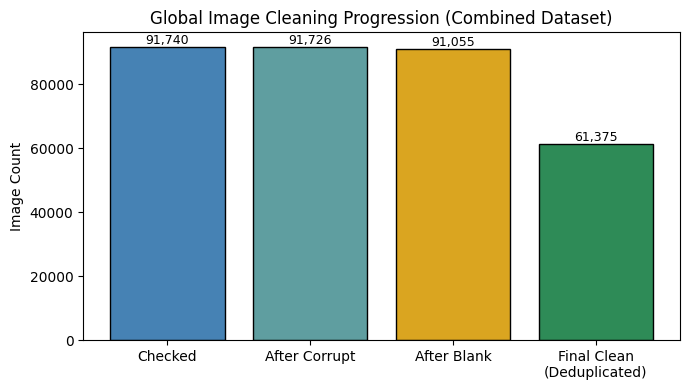

In [15]:
def calc_exact_rgb_hash(img_pil):
    thumb_rgb = img_pil.convert('RGB').resize((64, 64), Image.Resampling.NEAREST)
    return hashlib.md5(np.asarray(thumb_rgb, dtype=np.uint8).tobytes()).hexdigest()

def run_global_cleaning(raw_df, cfg):
    df_work = raw_df.sample(frac=1.0, random_state=cfg['seed']).reset_index(drop=True)

    if cfg['max_per_class'] is not None and cfg['max_per_class'] > 0:
        parts = []
        for lbl, grp in df_work.groupby('label'):
            n_take = min(len(grp), int(cfg['max_per_class']))
            parts.append(grp.sample(n=n_take, random_state=cfg['seed']))
        df_work = pd.concat(parts, ignore_index=True).sample(frac=1.0, random_state=cfg['seed']).reset_index(drop=True)

    n_checked = len(df_work)
    corruptCnt, blankCnt, dupCnt = 0, 0, 0
    seenHashes = {}
    clean_rows = []
    dup_pairs = []

    for idx, r in tqdm(df_work.iterrows(), total=n_checked, desc='Auditing & cleaning images', unit='img'):
        try:
            with Image.open(r['path']) as im:
                w, h = im.size
                rgb = im.convert('RGB')
                thumb = rgb.resize((64, 64), Image.Resampling.BILINEAR)
                arr = np.asarray(thumb, dtype=np.float32)
                h_val = calc_exact_rgb_hash(rgb)
        except Exception:
            if cfg['drop_corrupted']:
                corruptCnt += 1
            continue

        std_v = float(arr.std())
        if cfg['drop_blank'] and std_v < float(cfg['blank_thresh']):
            blankCnt += 1
            continue

        if cfg['drop_duplicates']:
            if h_val in seenHashes:
                dupCnt += 1
                if len(dup_pairs) < 4:
                    dup_pairs.append((seenHashes[h_val], r['path'], r['file']))
                continue
            seenHashes[h_val] = r['path']

        gray = arr.mean(axis=2)
        gx = np.abs(np.diff(gray, axis=1)).mean()
        gy = np.abs(np.diff(gray, axis=0)).mean()

        clean_rows.append({
            **r,
            'width': w,
            'height': h,
            'aspect_ratio': round(w / max(h, 1), 3),
            'brightness': round(float(arr.mean()), 2),
            'contrast': round(std_v, 2),
            'red_mean': round(float(arr[:, :, 0].mean()), 2),
            'green_mean': round(float(arr[:, :, 1].mean()), 2),
            'blue_mean': round(float(arr[:, :, 2].mean()), 2),
            'edge_strength': round(float((gx + gy) / 2.0), 3),
            'img_hash': h_val
        })

    clean_df = pd.DataFrame(clean_rows)
    summary = {
        'total_raw_indexed': len(raw_df),
        'sampled_for_cleaning': n_checked,
        'corrupted_removed': corruptCnt,
        'blank_removed': blankCnt,
        'duplicates_removed': dupCnt,
        'final_clean_images': len(clean_df)
    }
    return clean_df, summary, dup_pairs

clean_df, clean_summary, dup_sample_pairs = run_global_cleaning(pooled_raw_df, clean_config)
print('--- Global Image Cleaning Summary (R2) ---')
for k, v in clean_summary.items():
    print(f'  {k:24s}: {v:,}')

print('\nClean images by source & class:')
display(pd.crosstab(clean_df['source'], clean_df['class_name'], margins=True))

plt.figure(figsize=(7, 4))
stages = ['Checked', 'After Corrupt', 'After Blank', 'Final Clean\n(Deduplicated)']
vals = [
    clean_summary['sampled_for_cleaning'],
    clean_summary['sampled_for_cleaning'] - clean_summary['corrupted_removed'],
    clean_summary['sampled_for_cleaning'] - clean_summary['corrupted_removed'] - clean_summary['blank_removed'],
    clean_summary['final_clean_images']
]
bars = plt.bar(stages, vals, color=['steelblue', 'cadetblue', 'goldenrod', 'seagreen'], edgecolor='black')
plt.title('Global Image Cleaning Progression (Combined Dataset)')
plt.ylabel('Image Count')
for b in bars:
    plt.text(b.get_x() + b.get_width()/2, b.get_height(), f'{int(b.get_height()):,}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

Surviving clean counts per class: {'legitimate': 50942, 'phishing': 10433}
Enter target images per class AFTER cleaning (0 = keep all {'legitimate': 50942, 'phishing': 10433}) [default=0]: 8000

Class counts before post-clean selection : {'legitimate': 50942, 'phishing': 10433} (Total=61,375)
Class counts after post-clean selection  : {'phishing': 8000, 'legitimate': 8000} (Total=16,000)

--- Final Stratified Random Split Breakdown ---


class_name,legitimate,phishing,All
new_split,,,
test,1200,1200,2400
train,5600,5600,11200
val,1200,1200,2400
All,8000,8000,16000


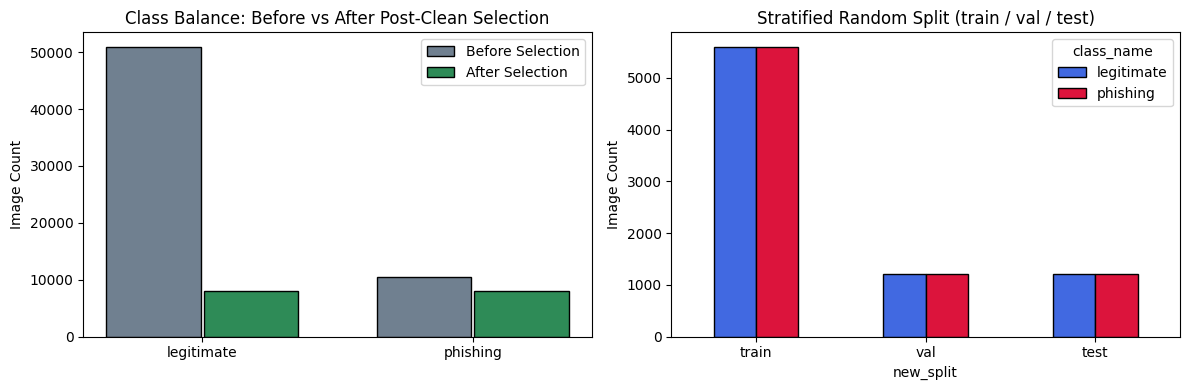

In [16]:
# Apply Data Subsampling (Class Balancing & Fractional Subsampling) and Random Stratified Split
pre_sub_counts = clean_df['class_name'].value_counts().to_dict()
print('Surviving clean counts per class:', pre_sub_counts)

sub_df = clean_df.copy()

# 1. Apply 'post_clean_per_class' from Step 03 (or allow setting it now after seeing clean counts)
cap_after = clean_config.get('post_clean_per_class')
if cap_after is None or cap_after == 0:
    override_cap = input(f"Enter target images per class AFTER cleaning (0 = keep all {pre_sub_counts}) [default=0]: ").strip()
    if override_cap.isdigit() and int(override_cap) > 0:
        cap_after = int(override_cap)
        clean_config['post_clean_per_class'] = cap_after

if cap_after is not None and cap_after > 0:
    sub_df = pd.concat([
        grp.sample(n=min(len(grp), int(cap_after)), random_state=clean_config['seed'])
        for _, grp in sub_df.groupby('label')
    ], ignore_index=True).sample(frac=1.0, random_state=clean_config['seed']).reset_index(drop=True)

# 2. Optional 50/50 balance after cleaning
if clean_config['balance_classes'] and sub_df['label'].nunique() > 1:
    min_cls_count = int(sub_df['label'].value_counts().min())
    sub_df = pd.concat([
        grp.sample(n=min_cls_count, random_state=clean_config['seed'])
        for _, grp in sub_df.groupby('label')
    ], ignore_index=True).sample(frac=1.0, random_state=clean_config['seed']).reset_index(drop=True)

# 3. Optional stratified fractional subsampling
if clean_config['subsample_ratio'] < 1.0:
    sub_df, _ = train_test_split(
        sub_df,
        train_size=clean_config['subsample_ratio'],
        stratify=sub_df['label'],
        random_state=clean_config['seed']
    )
    sub_df = sub_df.reset_index(drop=True)

post_sub_counts = sub_df['class_name'].value_counts().to_dict()
print(f'\nClass counts before post-clean selection : {pre_sub_counts} (Total={len(clean_df):,})')
print(f'Class counts after post-clean selection  : {post_sub_counts} (Total={len(sub_df):,})')

# 4. Stratified random split into train, val, and test
tr_val_df, test_df = train_test_split(
    sub_df, test_size=clean_config['test_ratio'],
    stratify=sub_df['label'], random_state=clean_config['seed']
)
rel_val_ratio = clean_config['val_ratio'] / (1.0 - clean_config['test_ratio'])
train_df, val_df = train_test_split(
    tr_val_df, test_size=rel_val_ratio,
    stratify=tr_val_df['label'], random_state=clean_config['seed']
)

train_df = train_df.copy(); train_df['new_split'] = 'train'
val_df   = val_df.copy();   val_df['new_split']   = 'val'
test_df  = test_df.copy();  test_df['new_split']  = 'test'

split_combined_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
print('\n--- Final Stratified Random Split Breakdown ---')
display(pd.crosstab(split_combined_df['new_split'], split_combined_df['class_name'], margins=True))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
cls_names = ['legitimate', 'phishing']
x_p = np.arange(len(cls_names))
ax[0].bar(x_p - 0.18, [pre_sub_counts.get(c, 0) for c in cls_names], width=0.35, label='Before Selection', color='slategray', edgecolor='black')
ax[0].bar(x_p + 0.18, [post_sub_counts.get(c, 0) for c in cls_names], width=0.35, label='After Selection', color='seagreen', edgecolor='black')
ax[0].set_xticks(x_p); ax[0].set_xticklabels(cls_names)
ax[0].set_title('Class Balance: Before vs After Post-Clean Selection'); ax[0].set_ylabel('Image Count'); ax[0].legend()

ct_plot = pd.crosstab(split_combined_df['new_split'], split_combined_df['class_name']).reindex(['train', 'val', 'test'])
ct_plot.plot(kind='bar', ax=ax[1], color=['royalblue', 'crimson'], edgecolor='black', rot=0)
ax[1].set_title('Stratified Random Split (train / val / test)'); ax[1].set_ylabel('Image Count')
plt.tight_layout()
plt.show()

---
## Step 05: *Visual Exploratory Data Analysis (EDA) (R2)*
Before training any neural network, we analyze visual domain descriptors extracted from the cleaned screenshots—including **brightness**, **contrast**, **RGB channel intensities**, **spatial edge density (layout complexity)**, and **aspect ratios**—alongside a visual gallery of real legitimate and phishing webpage renders.

--- Visual Descriptor Statistics by Class ---


class_name            legitimate  phishing
brightness    count     50942.00  10433.00
              mean        180.71    189.77
              median      203.64    228.22
              std          66.32     73.32
              min           0.04      0.04
              max         254.96    254.96
contrast      count     50942.00  10433.00
              mean         55.44     44.11
              median       56.42     39.04
              std          28.39     30.08
              min           1.00      1.00
              max         124.27    123.59
red_mean      count     50942.00  10433.00
              mean        178.44    188.76
              median      202.93    228.45
              std          68.64     75.58
              min           0.00      0.04
              max         255.00    254.96
green_mean    count     50942.00  10433.00
              mean        180.66    189.83
              median      204.24    228.32
              std          67.00     73.37
              min           0.00      0.00
              max         254.96    254.96
blue_mean     count     50942.00  10433.00
              mean        183.03    190.71
              median      206.99    231.77
              std          66.25     74.53
              min           0.05      0.00
              max         255.00    254.98
edge_strength count     50942.00  10433.00
              mean          6.94      4.62
              median        6.35      3.85
              std           4.07      3.57
              min           0.00      0.00
              max          35.98     22.37
aspect_ratio  count     50942.00  10433.00
              mean          1.43      1.73
              median        1.78      1.78
              std           0.54      0.20
              min           0.02      0.21
              max          21.66      5.24

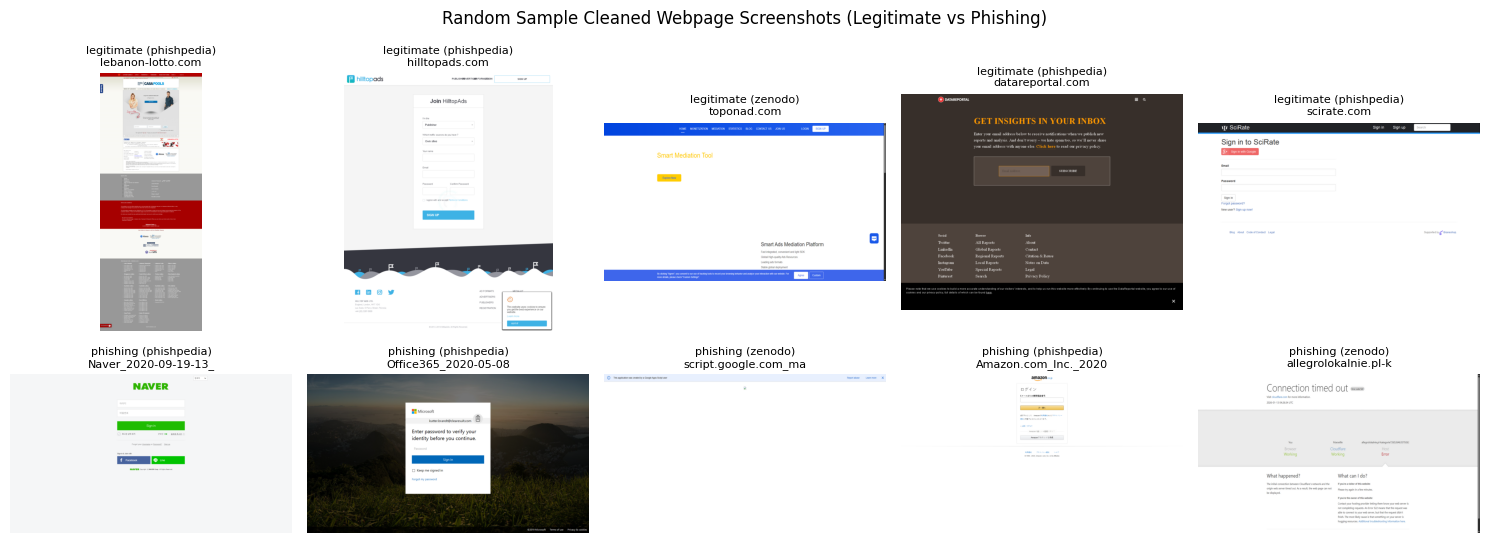

In [17]:
# Part 5A: Summary Statistics Table & Sample Webpage Screenshots Gallery
eda_features = ['brightness', 'contrast', 'red_mean', 'green_mean', 'blue_mean', 'edge_strength', 'aspect_ratio']
print('--- Visual Descriptor Statistics by Class ---')
stats_table = clean_df.groupby('class_name')[eda_features].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)
display(stats_table.T)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for r_i, cname in enumerate(['legitimate', 'phishing']):
    sub_imgs = clean_df[clean_df['class_name'] == cname].sample(n=min(5, len(clean_df[clean_df['class_name'] == cname])), random_state=clean_config['seed'])
    for c_i, (_, row_d) in enumerate(sub_imgs.iterrows()):
        with Image.open(row_d['path']) as im:
            axes[r_i, c_i].imshow(im.convert('RGB'))
        axes[r_i, c_i].set_title(f"{cname} ({row_d['source']})\n{str(row_d['domain'])[:20]}", fontsize=8)
        axes[r_i, c_i].axis('off')
plt.suptitle('Random Sample Cleaned Webpage Screenshots (Legitimate vs Phishing)')
plt.tight_layout()
plt.show()

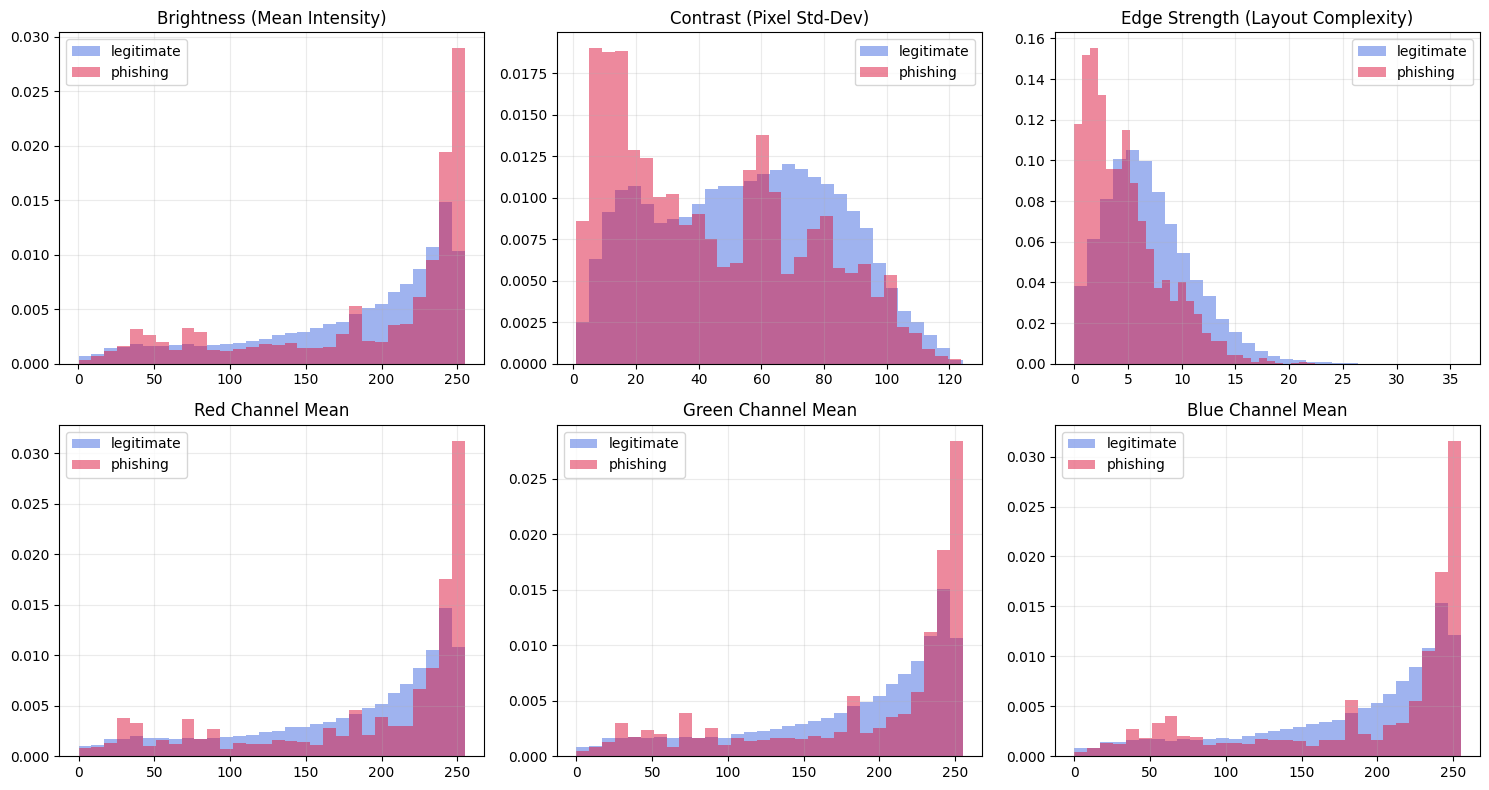

/tmp/ipykernel_532/2213017955.py:18: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  clean_df.boxplot(column=['brightness', 'contrast', 'red_mean', 'green_mean', 'blue_mean'], by='class_name', ax=ax[0])


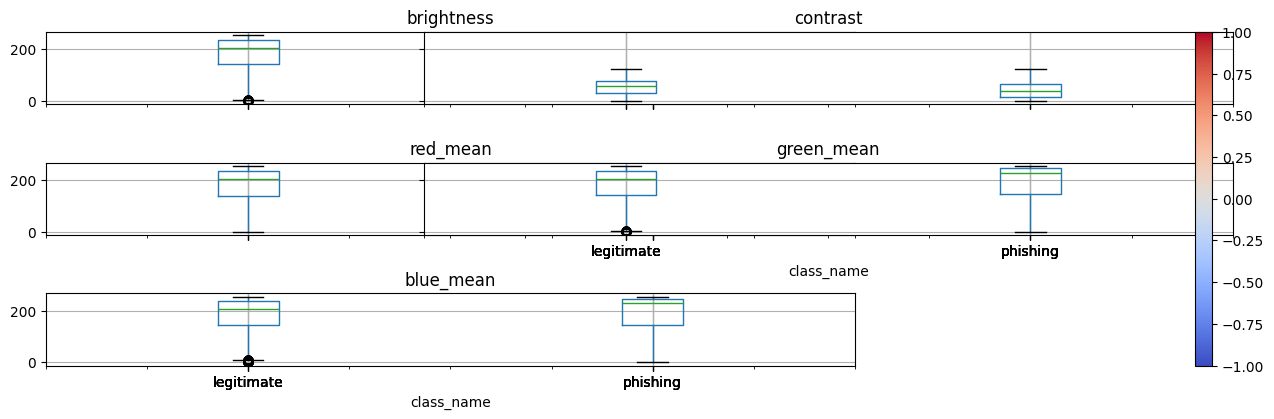

In [18]:
# Part 5B: Visual Feature Distributions, Boxplots & Correlation Matrix
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
plot_cols = ['brightness', 'contrast', 'edge_strength', 'red_mean', 'green_mean', 'blue_mean']
titles = ['Brightness (Mean Intensity)', 'Contrast (Pixel Std-Dev)', 'Edge Strength (Layout Complexity)',
          'Red Channel Mean', 'Green Channel Mean', 'Blue Channel Mean']

for idx, (col_name, title_txt) in enumerate(zip(plot_cols, titles)):
    ax = axes[idx // 3, idx % 3]
    for cname, clr in [('legitimate', 'royalblue'), ('phishing', 'crimson')]:
        sub = clean_df[clean_df['class_name'] == cname]
        ax.hist(sub[col_name], bins=30, alpha=0.5, label=cname, color=clr, density=True)
    ax.set_title(title_txt)
    ax.legend(); ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
clean_df.boxplot(column=['brightness', 'contrast', 'red_mean', 'green_mean', 'blue_mean'], by='class_name', ax=ax[0])
ax[0].set_title('Visual Intensity Boxplots by Class')
plt.suptitle('')

corr_mat = clean_df[eda_features + ['label']].corr()
im = ax[1].imshow(corr_mat.values, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax[1], fraction=0.046)
cols_c = corr_mat.columns.tolist()
ax[1].set_xticks(range(len(cols_c))); ax[1].set_yticks(range(len(cols_c)))
ax[1].set_xticklabels(cols_c, rotation=40, ha='right', fontsize=8)
ax[1].set_yticklabels(cols_c, fontsize=8)
ax[1].set_title('Correlation Matrix of Visual Image Features')
for i in range(len(cols_c)):
    for j in range(len(cols_c)):
        ax[1].text(j, i, f'{corr_mat.values[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.tight_layout()
plt.show()

---
## Step 06: *Custom 2D-CNN architecture configuration & model assembly (R4)*
Here you interactively define the convolutional feature extractor (`n_conv` blocks and filters per layer), the fully-connected classification head (`n_dense` layers and nodes per layer), activation function, dropout rate, optimizer, and learning rate. The model dynamically computes the flattened tensor size so any layer combination compiles cleanly.

In [19]:
# Interactive input for Custom 2D-CNN Architecture & Hyperparameters

def ask_val(prompt_txt, default_val, cast_type=str):
    raw = input(f'{prompt_txt} [default={default_val}]: ').strip()
    if raw == '':
        return default_val
    if cast_type == bool:
        return raw.lower() in ('true', '1', 'yes', 'y')
    if cast_type == int and raw.lower() in ('none', 'all', '0'):
        return None
    try:
        return cast_type(raw)
    except Exception:
        print(f'  Invalid input, using default: {default_val}')
        return default_val


print('=== Configure Custom 2D-CNN Architecture & Hyperparameters ===')
print('(Press Enter on any prompt to keep the default value shown in brackets)\n')

n_conv = ask_val('How many Convolutional (Conv2d) layers?', 3, int)
n_conv = max(1, min(6, n_conv if n_conv else 3))
default_filters = [32, 64, 128, 256, 256, 512]
conv_filters = []
for i in range(n_conv):
    f_cnt = ask_val(f'  -> Number of filters in Conv Layer {i+1}', default_filters[i], int)
    conv_filters.append(max(4, f_cnt))

kernel_sz  = ask_val('Conv kernel size (e.g. 3 for 3x3, 5 for 5x5)', 3, int)
pool_type  = ask_val('Pooling type (max or avg)', 'max', str).lower()
use_bn     = ask_val('Use Batch Normalization? (y/n)', True, bool)

n_dense = ask_val('\nHow many Fully-Connected (Dense) hidden layers?', 2, int)
n_dense = max(1, min(5, n_dense if n_dense else 2))
default_nodes = [256, 64, 32, 16, 16]
dense_nodes = []
for i in range(n_dense):
    n_cnt = ask_val(f'  -> Number of nodes in Dense Hidden Layer {i+1}', default_nodes[i], int)
    dense_nodes.append(max(4, n_cnt))

act_fn     = ask_val('Activation function (relu, leaky_relu, elu, tanh, gelu)', 'relu', str).lower()
dropout_p  = ask_val('Dropout rate (0.0 to 0.7)', 0.3, float)

opt_name   = ask_val('\nOptimizer (adam, adamw, sgd, rmsprop)', 'adam', str).lower()
lr_val     = ask_val('Learning rate (e.g. 0.001, 0.0005)', 0.001, float)
wd_val     = ask_val('Weight decay / L2 regularization (e.g. 0.0001)', 1e-4, float)
mom_val    = ask_val('Momentum (used if sgd/rmsprop)', 0.9, float)
batch_sz   = ask_val('Batch size (e.g. 32, 64, 128)', 64, int)
n_epochs   = ask_val('Number of training epochs', 12, int)

params = {
    **clean_config,
    'conv_filters': conv_filters,
    'kernel_size': kernel_sz,
    'stride': 1,
    'padding': kernel_sz // 2,
    'batch_norm': use_bn,
    'pool_type': 'avg' if pool_type == 'avg' else 'max',
    'pool_size': 2,
    'dense_nodes': dense_nodes,
    'activation': act_fn,
    'dropout': dropout_p,
    'optimizer': opt_name,
    'lr': lr_val,
    'weight_decay': wd_val,
    'momentum': mom_val,
    'batch_size': batch_sz,
    'epochs': n_epochs
}
print('\nArchitecture & Training Setup Saved:', params)

=== Configure Custom 2D-CNN Architecture & Hyperparameters ===
(Press Enter on any prompt to keep the default value shown in brackets)

How many Convolutional (Conv2d) layers? [default=3]: 3
  -> Number of filters in Conv Layer 1 [default=32]: 32
  -> Number of filters in Conv Layer 2 [default=64]: 64
  -> Number of filters in Conv Layer 3 [default=128]: 128
Conv kernel size (e.g. 3 for 3x3, 5 for 5x5) [default=3]: 3
Pooling type (max or avg) [default=max]: 
Use Batch Normalization? (y/n) [default=True]: y

How many Fully-Connected (Dense) hidden layers? [default=2]: 2
  -> Number of nodes in Dense Hidden Layer 1 [default=256]: 128
  -> Number of nodes in Dense Hidden Layer 2 [default=64]: 32
Activation function (relu, leaky_relu, elu, tanh, gelu) [default=relu]: leaky_relu
Dropout rate (0.0 to 0.7) [default=0.3]: 0.45

Optimizer (adam, adamw, sgd, rmsprop) [default=adam]: adamw
Learning rate (e.g. 0.001, 0.0005) [default=0.001]: 0.0003
Weight decay / L2 regularization (e.g. 0.0001) [d

In [20]:
# Build PyTorch DataLoaders & Instantiate Dynamic PhishCNN
class ScreenshotDataset(Dataset):
    def __init__(self, df_sub, img_size=(64, 64), channels=3):
        self.paths = df_sub['path'].tolist()
        self.labels = df_sub['label'].astype(np.int64).tolist()
        self.domains = df_sub['domain'].tolist()
        self.img_size = img_size
        self.channels = channels

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        p = self.paths[idx]
        with Image.open(p) as im:
            if self.channels == 1:
                im_r = im.convert('L').resize((self.img_size[1], self.img_size[0]), Image.Resampling.BILINEAR)
                arr = np.asarray(im_r, dtype=np.float32)[None, :, :] / 255.0
            else:
                im_r = im.convert('RGB').resize((self.img_size[1], self.img_size[0]), Image.Resampling.BILINEAR)
                arr = np.asarray(im_r, dtype=np.float32).transpose(2, 0, 1) / 255.0
        return torch.from_numpy(arr), torch.tensor(self.labels[idx], dtype=torch.long)

def pick_activation(act_name):
    if act_name == 'leaky_relu': return nn.LeakyReLU(0.1)
    if act_name == 'elu': return nn.ELU()
    if act_name == 'tanh': return nn.Tanh()
    if act_name == 'gelu': return nn.GELU()
    return nn.ReLU()

class PhishCNN(nn.Module):
    def __init__(self, p, n_classes=2):
        super().__init__()
        self.conv_layers = nn.ModuleList()
        in_c = p['channels']
        k, s, pad, ps = p['kernel_size'], p['stride'], p['padding'], p['pool_size']

        for out_c in p['conv_filters']:
            block = [nn.Conv2d(in_c, out_c, kernel_size=k, stride=s, padding=pad)]
            if p['batch_norm']:
                block.append(nn.BatchNorm2d(out_c))
            block.append(pick_activation(p['activation']))
            block.append(nn.AvgPool2d(ps, ps) if p['pool_type'] == 'avg' else nn.MaxPool2d(ps, ps))
            self.conv_layers.append(nn.Sequential(*block))
            in_c = out_c

        with torch.no_grad():
            tmp = torch.zeros(1, p['channels'], p['img_size'][0], p['img_size'][1])
            for b in self.conv_layers:
                tmp = b(tmp)
            self.flat_size = int(tmp.numel())

        fc = [nn.Flatten()]
        in_f = self.flat_size
        for nodes in p['dense_nodes']:
            fc.append(nn.Linear(in_f, nodes))
            if p['batch_norm']:
                fc.append(nn.BatchNorm1d(nodes))
            fc.append(pick_activation(p['activation']))
            if p['dropout'] > 0:
                fc.append(nn.Dropout(p['dropout']))
            in_f = nodes

        fc.append(nn.Linear(in_f, n_classes))
        self.fc_layers = nn.Sequential(*fc)

    def get_feature_maps(self, x):
        fmaps = []
        for b in self.conv_layers:
            x = b(x)
            fmaps.append(x)
        return fmaps

    def forward(self, x):
        for b in self.conv_layers:
            x = b(x)
        return self.fc_layers(x)

train_data = ScreenshotDataset(train_df, params['img_size'], params['channels'])
val_data   = ScreenshotDataset(val_df,   params['img_size'], params['channels'])
test_data  = ScreenshotDataset(test_df,  params['img_size'], params['channels'])

train_loader = DataLoader(train_data, batch_size=params['batch_size'], shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_data,   batch_size=params['batch_size'], shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_data,  batch_size=params['batch_size'], shuffle=False, num_workers=2, pin_memory=True)

cnn_net = PhishCNN(params).to(device)
n_params = sum(p.numel() for p in cnn_net.parameters() if p.requires_grad)

layer_rows = [{'Layer_Parameter': name, 'Tensor_Shape': str(list(param.shape)), 'Param_Count': param.numel()}
              for name, param in cnn_net.named_parameters() if param.requires_grad]
print(f'Total Trainable Parameters: {n_params:,}')
display(pd.DataFrame(layer_rows))

Total Trainable Parameters: 4,292,642


,Layer_Parameter,Tensor_Shape,Param_Count
0,conv_layers.0.0.weight,"[32, 3, 3, 3]",864
1,conv_layers.0.0.bias,[32],32
2,conv_layers.0.1.weight,[32],32
3,conv_layers.0.1.bias,[32],32
4,conv_layers.1.0.weight,"[64, 32, 3, 3]",18432
5,conv_layers.1.0.bias,[64],64
6,conv_layers.1.1.weight,[64],64
7,conv_layers.1.1.bias,[64],64
8,conv_layers.2.0.weight,"[128, 64, 3, 3]",73728
9,conv_layers.2.0.bias,[128],128


---
## Step 07: *Training the custom 2D-CNN & held-out test evaluation (R4)*
We train `PhishCNN` using class-balanced Cross-Entropy Loss, checkpointing the weights that achieve the highest validation F1-score. Afterward, we evaluate on the unseen `test` split across 24 classification, calibration, and latency metrics.

In [21]:
import warnings
from PIL import Image

# Increase PIL pixel limit for tall full-page webpage screenshots & suppress DecompressionBombWarning
Image.MAX_IMAGE_PIXELS = None
warnings.filterwarnings("ignore", category=Image.DecompressionBombWarning)

In [22]:
# Training loop for Custom PhishCNN
def make_optimizer(net, p):
    opt = p['optimizer'].lower()
    lr, wd = float(p['lr']), float(p['weight_decay'])
    if opt == 'sgd': return optim.SGD(net.parameters(), lr=lr, momentum=float(p['momentum']), weight_decay=wd)
    if opt == 'rmsprop': return optim.RMSprop(net.parameters(), lr=lr, momentum=float(p['momentum']), weight_decay=wd)
    if opt == 'adamw': return optim.AdamW(net.parameters(), lr=lr, weight_decay=wd)
    return optim.Adam(net.parameters(), lr=lr, weight_decay=wd)

def eval_loader(net, loader, loss_fn):
    net.eval()
    total_loss = 0.0
    preds_list, probs_list, y_list = [], [], []
    t0 = time.time()
    with torch.no_grad():
        for x_b, y_b in loader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            out = net(x_b)
            loss = loss_fn(out, y_b)
            prob = torch.softmax(out, dim=1)[:, 1]
            pred = torch.argmax(out, dim=1)
            total_loss += loss.item() * len(y_b)
            preds_list.extend(pred.cpu().numpy())
            probs_list.extend(prob.cpu().numpy())
            y_list.extend(y_b.cpu().numpy())
    infer_sec = time.time() - t0
    avg_l = total_loss / max(len(y_list), 1)
    acc = accuracy_score(y_list, preds_list)
    f1_v = f1_score(y_list, preds_list, zero_division=0)
    return avg_l, acc, f1_v, np.array(y_list), np.array(preds_list), np.array(probs_list), infer_sec

cls_counts_tr = np.bincount(train_df['label'].values)
cls_weights = torch.tensor(len(train_df) / (2.0 * np.maximum(cls_counts_tr, 1)), dtype=torch.float32).to(device)
loss_fn = nn.CrossEntropyLoss(weight=cls_weights)
optimizer = make_optimizer(cnn_net, params)

epoch_rows = []
best_val_f1, best_weights = -1.0, None
t_start = time.time()

for ep in range(1, params['epochs'] + 1):
    t_ep = time.time()
    cnn_net.train()
    ep_loss, correct, total = 0.0, 0, 0
    tr_preds_all, tr_y_all = [], []

    for x_b, y_b in train_loader:
        x_b, y_b = x_b.to(device), y_b.to(device)
        optimizer.zero_grad()
        out = cnn_net(x_b)
        loss = loss_fn(out, y_b)
        loss.backward()
        optimizer.step()

        ep_loss += loss.item() * len(y_b)
        pr = torch.argmax(out, dim=1)
        correct += (pr == y_b).sum().item()
        total += len(y_b)
        tr_preds_all.extend(pr.cpu().numpy())
        tr_y_all.extend(y_b.cpu().numpy())

    tr_l = ep_loss / max(total, 1)
    tr_a = correct / max(total, 1)
    tr_f1 = f1_score(tr_y_all, tr_preds_all, zero_division=0)
    val_l, val_a, val_f1, _, _, _, _ = eval_loader(cnn_net, val_loader, loss_fn)
    ep_sec = round(time.time() - t_ep, 2)

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_weights = {k: v.cpu().clone() for k, v in cnn_net.state_dict().items()}

    epoch_rows.append({
        'Epoch': ep, 'Train_Loss': round(tr_l, 4), 'Val_Loss': round(val_l, 4),
        'Train_Acc': round(tr_a, 4), 'Val_Acc': round(val_a, 4),
        'Train_F1': round(tr_f1, 4), 'Val_F1': round(val_f1, 4),
        'Overfit_Gap': round(tr_a - val_a, 4), 'Time_s': ep_sec
    })
    print(f"Epoch {ep:02d}/{params['epochs']:02d} | TrLoss: {tr_l:.4f}, TrAcc: {tr_a*100:.2f}%, TrF1: {tr_f1:.4f} | ValLoss: {val_l:.4f}, ValAcc: {val_a*100:.2f}%, ValF1: {val_f1:.4f} ({ep_sec}s)")

train_time_sec = round(time.time() - t_start, 2)
if best_weights is not None:
    cnn_net.load_state_dict({k: v.to(device) for k, v in best_weights.items()})

epoch_history_df = pd.DataFrame(epoch_rows)
display(epoch_history_df)

Epoch 01/12 | TrLoss: 0.5729, TrAcc: 70.99%, TrF1: 0.7217 | ValLoss: 0.4787, ValAcc: 76.54%, ValF1: 0.7723 (358.69s)
Epoch 02/12 | TrLoss: 0.4635, TrAcc: 78.38%, TrF1: 0.7866 | ValLoss: 0.4341, ValAcc: 79.25%, ValF1: 0.7979 (352.76s)
Epoch 03/12 | TrLoss: 0.3966, TrAcc: 82.41%, TrF1: 0.8260 | ValLoss: 0.4171, ValAcc: 80.12%, ValF1: 0.8139 (356.09s)
Epoch 04/12 | TrLoss: 0.3542, TrAcc: 84.93%, TrF1: 0.8501 | ValLoss: 0.3812, ValAcc: 83.62%, ValF1: 0.8240 (353.37s)
Epoch 05/12 | TrLoss: 0.3116, TrAcc: 86.99%, TrF1: 0.8713 | ValLoss: 0.3569, ValAcc: 83.38%, ValF1: 0.8377 (353.15s)
Epoch 06/12 | TrLoss: 0.2672, TrAcc: 88.96%, TrF1: 0.8903 | ValLoss: 0.3806, ValAcc: 84.38%, ValF1: 0.8290 (351.72s)
Epoch 07/12 | TrLoss: 0.2257, TrAcc: 91.04%, TrF1: 0.9111 | ValLoss: 0.4295, ValAcc: 81.04%, ValF1: 0.8319 (349.18s)
Epoch 08/12 | TrLoss: 0.1982, TrAcc: 91.99%, TrF1: 0.9204 | ValLoss: 0.4551, ValAcc: 82.00%, ValF1: 0.8366 (349.66s)
Epoch 09/12 | TrLoss: 0.1711, TrAcc: 93.38%, TrF1: 0.9344 | ValL

,Epoch,Train_Loss,Val_Loss,Train_Acc,Val_Acc,Train_F1,Val_F1,Overfit_Gap,Time_s
0,1,0.5729,0.4787,0.7099,0.7654,0.7217,0.7723,-0.0555,358.69
1,2,0.4635,0.4341,0.7837,0.7925,0.7866,0.7979,-0.0088,352.76
2,3,0.3966,0.4171,0.8241,0.8013,0.8260,0.8139,0.0229,356.09
3,4,0.3542,0.3812,0.8493,0.8363,0.8501,0.8240,0.0130,353.37
4,5,0.3116,0.3569,0.8699,0.8337,0.8713,0.8377,0.0362,353.15
5,6,0.2672,0.3806,0.8896,0.8438,0.8903,0.8290,0.0459,351.72
6,7,0.2257,0.4295,0.9104,0.8104,0.9111,0.8319,0.0999,349.18
7,8,0.1982,0.4551,0.9199,0.8200,0.9204,0.8366,0.0999,349.66
8,9,0.1711,0.4059,0.9338,0.8596,0.9344,0.8510,0.0743,352.64
9,10,0.1508,0.4119,0.9419,0.8629,0.9423,0.8538,0.0790,353.27


In [23]:
# Held-out Test Set Evaluation & Complete Metrics Summary Table
test_loss, test_acc, test_f1, y_true, y_pred, y_prob, infer_sec = eval_loader(cnn_net, test_loader, loss_fn)

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)

bal_acc     = balanced_accuracy_score(y_true, y_pred)
prec_bin    = precision_score(y_true, y_pred, zero_division=0)
prec_macro  = precision_score(y_true, y_pred, average='macro', zero_division=0)
prec_weight = precision_score(y_true, y_pred, average='weighted', zero_division=0)
rec_bin     = recall_score(y_true, y_pred, zero_division=0)
rec_macro   = recall_score(y_true, y_pred, average='macro', zero_division=0)
f1_macro    = f1_score(y_true, y_pred, average='macro', zero_division=0)
f1_weight   = f1_score(y_true, y_pred, average='weighted', zero_division=0)
specificity = tn / max(tn + fp, 1)
fpr_val     = fp / max(fp + tn, 1)
fnr_val     = fn / max(fn + tp, 1)
mcc_val     = matthews_corrcoef(y_true, y_pred)
kappa_val   = cohen_kappa_score(y_true, y_pred)
auc_roc     = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else 0.0
auc_pr      = average_precision_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else 0.0
ms_per_img  = (infer_sec * 1000.0) / max(len(y_true), 1)

metrics_summary_df = pd.DataFrame([
    {'Metric': 'Test Accuracy', 'Value': round(test_acc, 4)},
    {'Metric': 'Balanced Accuracy', 'Value': round(bal_acc, 4)},
    {'Metric': 'Precision (Phishing / Binary)', 'Value': round(prec_bin, 4)},
    {'Metric': 'Precision (Macro Avg)', 'Value': round(prec_macro, 4)},
    {'Metric': 'Precision (Weighted Avg)', 'Value': round(prec_weight, 4)},
    {'Metric': 'Recall / Sensitivity (TPR)', 'Value': round(rec_bin, 4)},
    {'Metric': 'Recall (Macro Avg)', 'Value': round(rec_macro, 4)},
    {'Metric': 'Specificity (True Negative Rate)', 'Value': round(specificity, 4)},
    {'Metric': 'False Positive Rate (FPR)', 'Value': round(fpr_val, 4)},
    {'Metric': 'False Negative Rate (FNR)', 'Value': round(fnr_val, 4)},
    {'Metric': 'F1-Score (Phishing / Binary)', 'Value': round(test_f1, 4)},
    {'Metric': 'F1-Score (Macro Avg)', 'Value': round(f1_macro, 4)},
    {'Metric': 'F1-Score (Weighted Avg)', 'Value': round(f1_weight, 4)},
    {'Metric': 'ROC-AUC Score', 'Value': round(auc_roc, 4)},
    {'Metric': 'PR-AUC (Average Precision)', 'Value': round(auc_pr, 4)},
    {'Metric': 'Matthews Correlation Coeff (MCC)', 'Value': round(mcc_val, 4)},
    {'Metric': 'Cohens Kappa Score', 'Value': round(kappa_val, 4)},
    {'Metric': 'Test Cross-Entropy Loss', 'Value': round(test_loss, 4)},
    {'Metric': 'True Negatives (Legit Correct)', 'Value': int(tn)},
    {'Metric': 'False Positives (Legit -> Phish)', 'Value': int(fp)},
    {'Metric': 'False Negatives (Phish -> Legit)', 'Value': int(fn)},
    {'Metric': 'True Positives (Phish Correct)', 'Value': int(tp)},
    {'Metric': 'Total Training Time (s)', 'Value': train_time_sec},
    {'Metric': 'Inference Speed (ms / image)', 'Value': round(ms_per_img, 3)}
])

run_history_log.append({
    'Run': len(run_history_log) + 1,
    'Img_Size': f"{params['img_size'][0]}x{params['img_size'][1]}",
    'Conv_Layers': str(params['conv_filters']),
    'Dense_Layers': str(params['dense_nodes']),
    'Activation': params['activation'],
    'Dropout': params['dropout'],
    'Optimizer': params['optimizer'],
    'LR': params['lr'],
    'Batch': params['batch_size'],
    'Epochs': params['epochs'],
    'Params': n_params,
    'Accuracy': round(test_acc, 4),
    'Precision': round(prec_bin, 4),
    'Recall': round(rec_bin, 4),
    'Specificity': round(specificity, 4),
    'F1_Binary': round(test_f1, 4),
    'F1_Macro': round(f1_macro, 4),
    'ROC_AUC': round(auc_roc, 4),
    'PR_AUC': round(auc_pr, 4),
    'MCC': round(mcc_val, 4),
    'Time_s': train_time_sec
})

display(metrics_summary_df)
print(classification_report(y_true, y_pred, target_names=['legitimate (0)', 'phishing (1)'], digits=4))

,Metric,Value
0,Test Accuracy,0.8633
1,Balanced Accuracy,0.8633
2,Precision (Phishing / Binary),0.8707
3,Precision (Macro Avg),0.8635
4,Precision (Weighted Avg),0.8635
5,Recall / Sensitivity (TPR),0.8533
6,Recall (Macro Avg),0.8633
7,Specificity (True Negative Rate),0.8733
8,False Positive Rate (FPR),0.1267
9,False Negative Rate (FNR),0.1467


                precision    recall  f1-score   support

legitimate (0)     0.8562    0.8733    0.8647      1200
  phishing (1)     0.8707    0.8533    0.8620      1200

      accuracy                         0.8633      2400
     macro avg     0.8635    0.8633    0.8633      2400
  weighted avg     0.8635    0.8633    0.8633      2400



---
## Step 08: *Diagnostic evaluation curves, CNN explainability & error analysis (R4)*
This section visualizes:
1. **Convergence & Overfitting Gap Curves** across training epochs.
2. **Raw & Row-Normalized Confusion Matrices** and **Predicted Probability Distributions**.
3. **ROC Curve, Precision-Recall Curve, and Classification Threshold Sensitivity**.
4. **Visual Explainability**: Learned `Conv1` filter kernels, **Pixel Gradient Saliency Maps**, and **Layer-by-Layer Activation Heatmaps**.
5. **Misclassified Screenshot Error Gallery** and **Multi-Run Experiment Comparison Log**.

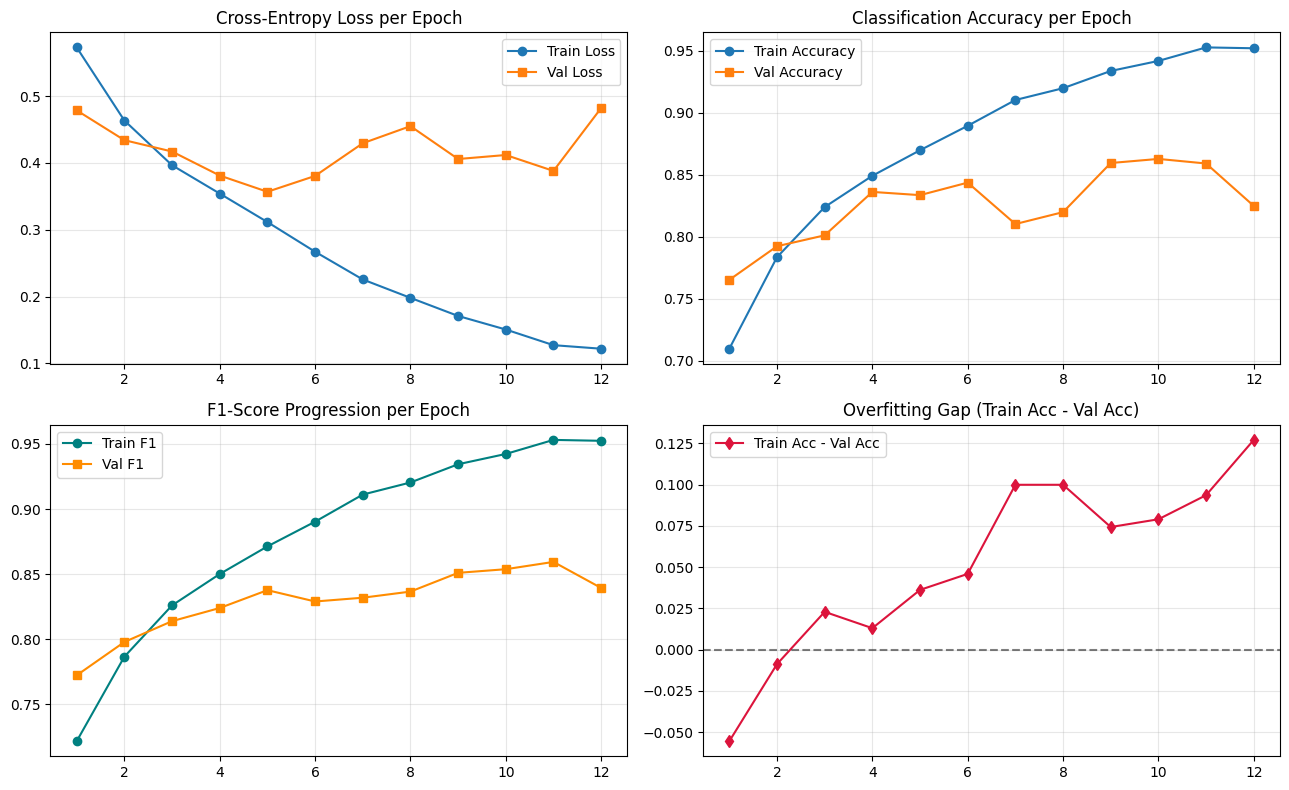

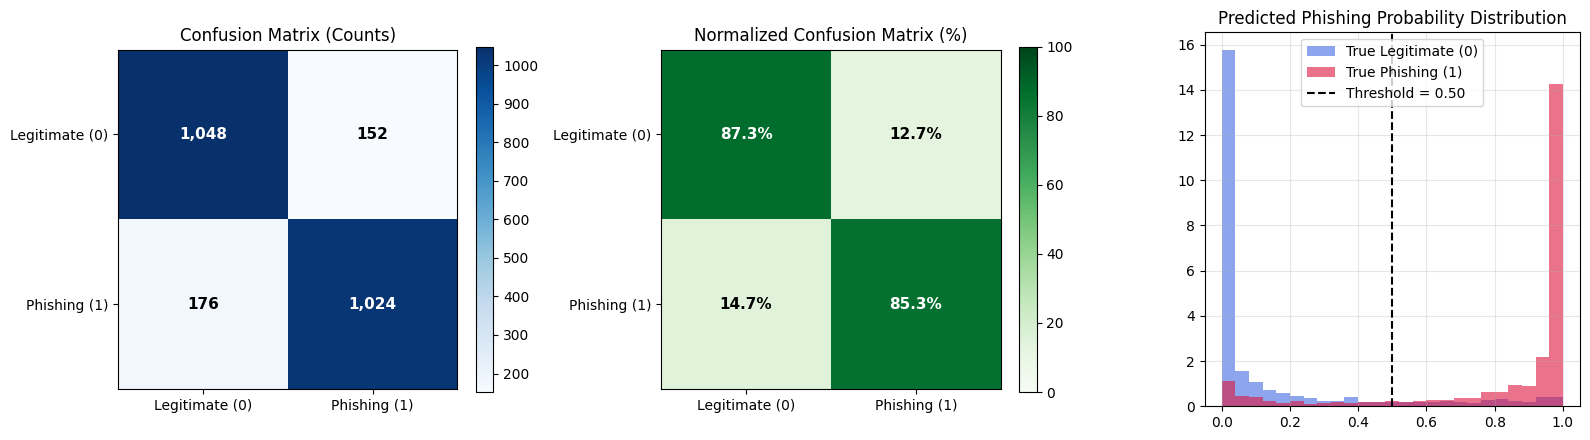

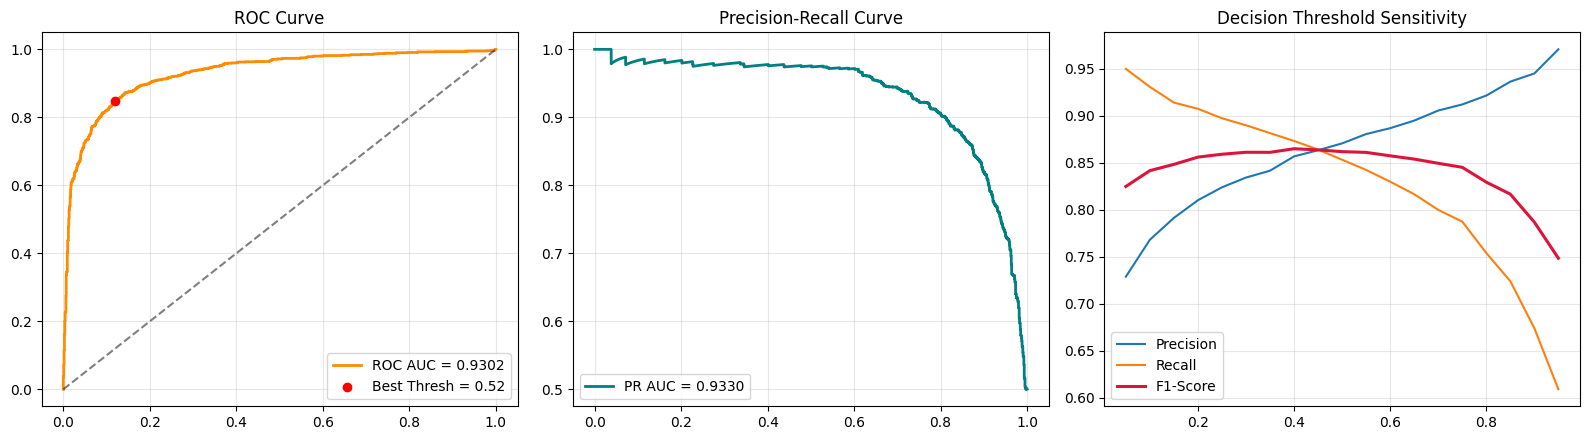

In [24]:
# Diagnostic Set A: Convergence Curves, Confusion Matrices & ROC / PR / Threshold Curves
ep_x = epoch_history_df['Epoch']
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
ax[0, 0].plot(ep_x, epoch_history_df['Train_Loss'], marker='o', label='Train Loss')
ax[0, 0].plot(ep_x, epoch_history_df['Val_Loss'], marker='s', label='Val Loss')
ax[0, 0].set_title('Cross-Entropy Loss per Epoch'); ax[0, 0].legend(); ax[0, 0].grid(True, alpha=0.3)

ax[0, 1].plot(ep_x, epoch_history_df['Train_Acc'], marker='o', label='Train Accuracy')
ax[0, 1].plot(ep_x, epoch_history_df['Val_Acc'], marker='s', label='Val Accuracy')
ax[0, 1].set_title('Classification Accuracy per Epoch'); ax[0, 1].legend(); ax[0, 1].grid(True, alpha=0.3)

ax[1, 0].plot(ep_x, epoch_history_df['Train_F1'], marker='o', color='teal', label='Train F1')
ax[1, 0].plot(ep_x, epoch_history_df['Val_F1'], marker='s', color='darkorange', label='Val F1')
ax[1, 0].set_title('F1-Score Progression per Epoch'); ax[1, 0].legend(); ax[1, 0].grid(True, alpha=0.3)

ax[1, 1].plot(ep_x, epoch_history_df['Overfit_Gap'], marker='d', color='crimson', label='Train Acc - Val Acc')
ax[1, 1].axhline(0, color='black', linestyle='--', alpha=0.5)
ax[1, 1].set_title('Overfitting Gap (Train Acc - Val Acc)'); ax[1, 1].legend(); ax[1, 1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# Confusion Matrices & Probability Histogram
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
im0 = ax[0].imshow(cm, cmap='Blues')
plt.colorbar(im0, ax=ax[0], fraction=0.046)
ax[0].set_xticks([0, 1]); ax[0].set_yticks([0, 1])
ax[0].set_xticklabels(['Legitimate (0)', 'Phishing (1)']); ax[0].set_yticklabels(['Legitimate (0)', 'Phishing (1)'])
ax[0].set_title('Confusion Matrix (Counts)')
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, f'{cm[i, j]:,}', ha='center', va='center',
                   color='white' if cm[i, j] > cm.max()/2 else 'black', fontweight='bold', fontsize=11)

cm_norm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100.0
im1 = ax[1].imshow(cm_norm, cmap='Greens', vmin=0, vmax=100)
plt.colorbar(im1, ax=ax[1], fraction=0.046)
ax[1].set_xticks([0, 1]); ax[1].set_yticks([0, 1])
ax[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)']); ax[1].set_yticklabels(['Legitimate (0)', 'Phishing (1)'])
ax[1].set_title('Normalized Confusion Matrix (%)')
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, f'{cm_norm[i, j]:.1f}%', ha='center', va='center',
                   color='white' if cm_norm[i, j] > 50 else 'black', fontweight='bold', fontsize=11)

ax[2].hist(y_prob[y_true == 0], bins=25, alpha=0.6, color='royalblue', label='True Legitimate (0)', density=True)
ax[2].hist(y_prob[y_true == 1], bins=25, alpha=0.6, color='crimson', label='True Phishing (1)', density=True)
ax[2].axvline(0.5, color='black', linestyle='--', label='Threshold = 0.50')
ax[2].set_title('Predicted Phishing Probability Distribution'); ax[2].legend(); ax[2].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# ROC, Precision-Recall & Threshold Sensitivity
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
fpr_arr, tpr_arr, roc_thresh = roc_curve(y_true, y_prob)
best_j_idx = int(np.argmax(tpr_arr - fpr_arr))
ax[0].plot(fpr_arr, tpr_arr, color='darkorange', lw=2, label=f'ROC AUC = {auc_roc:.4f}')
ax[0].scatter(fpr_arr[best_j_idx], tpr_arr[best_j_idx], color='red', zorder=5, label=f'Best Thresh = {roc_thresh[best_j_idx]:.2f}')
ax[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax[0].set_title('ROC Curve'); ax[0].legend(loc='lower right'); ax[0].grid(True, alpha=0.3)

p_arr, r_arr, _ = precision_recall_curve(y_true, y_prob)
ax[1].plot(r_arr, p_arr, color='teal', lw=2, label=f'PR AUC = {auc_pr:.4f}')
ax[1].set_title('Precision-Recall Curve'); ax[1].legend(loc='lower left'); ax[1].grid(True, alpha=0.3)

th_grid = np.linspace(0.05, 0.95, 19)
p_list = [precision_score(y_true, (y_prob >= t).astype(int), zero_division=0) for t in th_grid]
r_list = [recall_score(y_true, (y_prob >= t).astype(int), zero_division=0) for t in th_grid]
f1_list = [f1_score(y_true, (y_prob >= t).astype(int), zero_division=0) for t in th_grid]
ax[2].plot(th_grid, p_list, label='Precision'); ax[2].plot(th_grid, r_list, label='Recall')
ax[2].plot(th_grid, f1_list, label='F1-Score', lw=2.2, color='crimson')
ax[2].set_title('Decision Threshold Sensitivity'); ax[2].legend(); ax[2].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

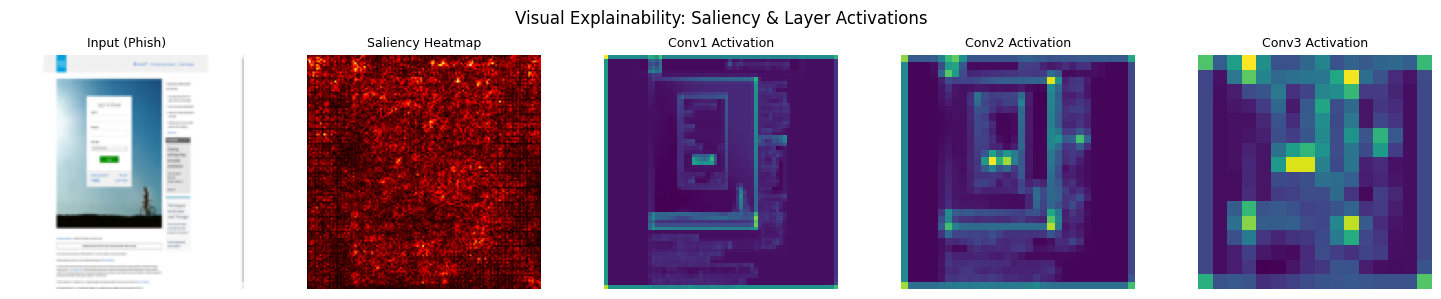

Misclassified Test Screenshots: 328 / 2400


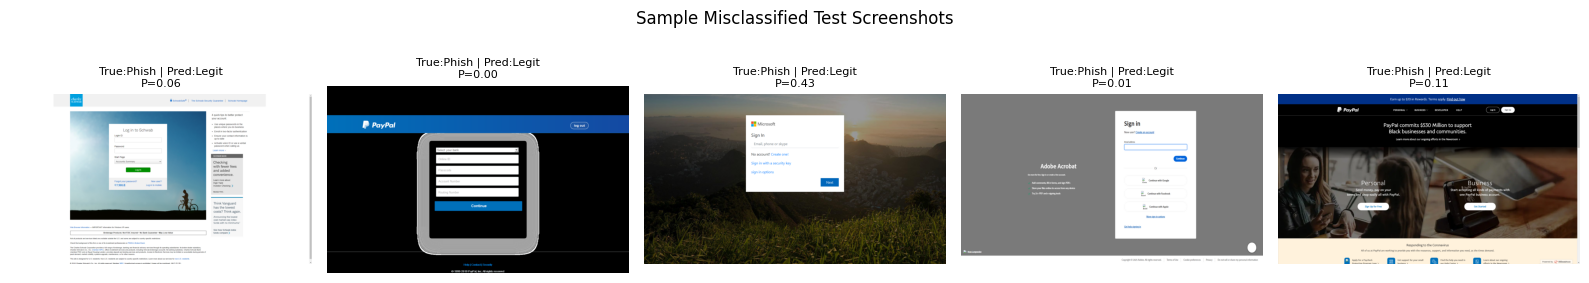

,Run,Img_Size,Conv_Layers,Dense_Layers,Activation,Dropout,Optimizer,LR,Batch,Epochs,...,Accuracy,Precision,Recall,Specificity,F1_Binary,F1_Macro,ROC_AUC,PR_AUC,MCC,Time_s
0,1,128x128,"[32, 64, 128]","[128, 32]",leaky_relu,0.45,adamw,0.0003,64,12,...,0.8633,0.8707,0.8533,0.8733,0.862,0.8633,0.9302,0.933,0.7268,4238.52


In [25]:
# Diagnostic Set B: CNN Feature Maps, Gradient Saliency Heatmap, Misclassified Errors & Run Log
cnn_net.eval()
sample_x, sample_y = test_data[0]
inp_tensor = sample_x.unsqueeze(0).to(device).requires_grad_(True)
logits_one = cnn_net(inp_tensor)
logits_one[0, int(torch.argmax(logits_one, dim=1).item())].backward()

saliency = inp_tensor.grad.data.abs().squeeze(0).cpu().numpy()
saliency_2d = saliency.max(axis=0) if saliency.ndim == 3 else saliency

with torch.no_grad():
    all_fmaps = cnn_net.get_feature_maps(sample_x.unsqueeze(0).to(device))

n_blocks = len(all_fmaps)
fig, axes = plt.subplots(1, n_blocks + 2, figsize=(3.0 * (n_blocks + 2), 3.0))
orig_disp = sample_x.numpy().transpose(1, 2, 0) if params['channels'] == 3 else sample_x.numpy()[0]
axes[0].imshow(orig_disp, cmap='gray' if params['channels'] == 1 else None)
axes[0].set_title(f"Input ({'Phish' if sample_y==1 else 'Legit'})", fontsize=9); axes[0].axis('off')
axes[1].imshow(saliency_2d, cmap='hot')
axes[1].set_title('Saliency Heatmap', fontsize=9); axes[1].axis('off')
for b_idx, fmap in enumerate(all_fmaps):
    axes[b_idx + 2].imshow(fmap.squeeze(0).mean(dim=0).cpu().numpy(), cmap='viridis')
    axes[b_idx + 2].set_title(f'Conv{b_idx+1} Activation', fontsize=9); axes[b_idx + 2].axis('off')
plt.suptitle('Visual Explainability: Saliency & Layer Activations')
plt.tight_layout(); plt.show()

# Misclassified Error Gallery
mis_idx = np.where(y_true != y_pred)[0]
print(f'Misclassified Test Screenshots: {len(mis_idx)} / {len(y_true)}')
if len(mis_idx) > 0:
    n_err = min(5, len(mis_idx))
    fig, axes = plt.subplots(1, n_err, figsize=(3.2 * n_err, 3.2))
    if n_err == 1: axes = [axes]
    for i in range(n_err):
        idx_e = int(mis_idx[i])
        row_e = test_df.iloc[idx_e]
        with Image.open(row_e['path']) as im:
            axes[i].imshow(im.convert('RGB'))
        axes[i].set_title(f"True:{'Phish' if y_true[idx_e]==1 else 'Legit'} | Pred:{'Phish' if y_pred[idx_e]==1 else 'Legit'}\nP={y_prob[idx_e]:.2f}", fontsize=8)
        axes[i].axis('off')
    plt.suptitle('Sample Misclassified Test Screenshots')
    plt.tight_layout(); plt.show()

exp_df = pd.DataFrame(run_history_log)
display(exp_df)
exp_df.to_csv('cnn_runs_comparison.csv', index=False)

---
## Step 09: *Benchmark comparison against ResNet-18, MobileNetV3-Small & EfficientNet-B0 (R4)*
Finally, we train and evaluate three established vision architectures—**ResNet-18**, **MobileNetV3-Small**, and **EfficientNet-B0**—on the exact same train/validation/test splits, and generate a master comparison table, overlaid ROC/PR curves, side-by-side confusion matrices, and parameter/latency efficiency plots.

In [26]:
import torchvision.models as tv_models

print('=== Configure Benchmark Models (ResNet-18, MobileNetV3-Small, EfficientNet-B0) ===')
use_pretrained = ask_val('Use pretrained ImageNet weights (Transfer Learning)? (y/n)', True, bool)
bench_epochs   = ask_val('Number of epochs for benchmark models', min(8, params['epochs']), int)
bench_lr       = ask_val('Learning rate for benchmark models', 0.0005, float)

def build_benchmark_model(arch_name, in_channels=3, num_classes=2, pretrained=True):
    if arch_name == 'ResNet-18':
        m = tv_models.resnet18(weights=tv_models.ResNet18_Weights.DEFAULT if pretrained else None)
        if in_channels != 3:
            oc = m.conv1
            m.conv1 = nn.Conv2d(in_channels, oc.out_channels, oc.kernel_size, oc.stride, oc.padding, bias=False)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        return m
    elif arch_name == 'MobileNetV3-Small':
        m = tv_models.mobilenet_v3_small(weights=tv_models.MobileNet_V3_Small_Weights.DEFAULT if pretrained else None)
        if in_channels != 3:
            oc = m.features[0][0]
            m.features[0][0] = nn.Conv2d(in_channels, oc.out_channels, oc.kernel_size, oc.stride, oc.padding, bias=False)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, num_classes)
        return m
    elif arch_name == 'EfficientNet-B0':
        m = tv_models.efficientnet_b0(weights=tv_models.EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        if in_channels != 3:
            oc = m.features[0][0]
            m.features[0][0] = nn.Conv2d(in_channels, oc.out_channels, oc.kernel_size, oc.stride, oc.padding, bias=False)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, num_classes)
        return m
    raise ValueError(arch_name)

benchmark_results = {
    'Custom PhishCNN (Ours)': {
        'params': n_params, 'train_time_s': train_time_sec, 'infer_ms': round(ms_per_img, 3),
        'test_loss': round(test_loss, 4), 'acc': round(test_acc, 4), 'bal_acc': round(bal_acc, 4),
        'prec': round(prec_bin, 4), 'rec': round(rec_bin, 4), 'spec': round(specificity, 4),
        'f1': round(test_f1, 4), 'f1_macro': round(f1_macro, 4), 'roc_auc': round(auc_roc, 4),
        'pr_auc': round(auc_pr, 4), 'mcc': round(mcc_val, 4), 'kappa': round(kappa_val, 4),
        'cm': cm, 'y_true': y_true, 'y_pred': y_pred, 'y_prob': y_prob, 'epoch_df': epoch_history_df
    }
}

for b_name in ['ResNet-18', 'MobileNetV3-Small', 'EfficientNet-B0']:
    print(f'\n--- Training Benchmark: {b_name} ---')
    b_net = build_benchmark_model(b_name, params['channels'], 2, use_pretrained).to(device)
    b_params = sum(p.numel() for p in b_net.parameters() if p.requires_grad)
    b_opt = optim.Adam(b_net.parameters(), lr=bench_lr, weight_decay=params['weight_decay'])
    b_loss_fn = nn.CrossEntropyLoss(weight=cls_weights)

    b_ep_rows, best_b_f1, best_b_w = [], -1.0, None
    t_b0 = time.time()
    for ep in range(1, bench_epochs + 1):
        t_e0 = time.time()
        b_net.train()
        ep_l, corr, tot = 0.0, 0, 0
        tr_p_l, tr_y_l = [], []
        for x_b, y_b in train_loader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            b_opt.zero_grad()
            out = b_net(x_b)
            loss = b_loss_fn(out, y_b)
            loss.backward()
            b_opt.step()
            ep_l += loss.item() * len(y_b)
            pr = torch.argmax(out, dim=1)
            corr += (pr == y_b).sum().item(); tot += len(y_b)
            tr_p_l.extend(pr.cpu().numpy()); tr_y_l.extend(y_b.cpu().numpy())

        val_l_b, val_a_b, val_f1_b, _, _, _, _ = eval_loader(b_net, val_loader, b_loss_fn)
        if val_f1_b > best_b_f1:
            best_b_f1 = val_f1_b
            best_b_w = {k: v.cpu().clone() for k, v in b_net.state_dict().items()}
        b_ep_rows.append({
            'Epoch': ep, 'Train_Loss': round(ep_l/max(tot,1), 4), 'Val_Loss': round(val_l_b, 4),
            'Train_Acc': round(corr/max(tot,1), 4), 'Val_Acc': round(val_a_b, 4),
            'Train_F1': round(f1_score(tr_y_l, tr_p_l, zero_division=0), 4), 'Val_F1': round(val_f1_b, 4)
        })
        print(f'  [{b_name}] Ep {ep:02d}/{bench_epochs:02d} -> ValAcc: {val_a_b*100:.2f}%, ValF1: {val_f1_b:.4f} ({time.time()-t_e0:.1f}s)')

    b_train_sec = round(time.time() - t_b0, 2)
    if best_b_w is not None:
        b_net.load_state_dict({k: v.to(device) for k, v in best_b_w.items()})
    b_tl, b_ta, b_tf1, b_yt, b_yp, b_yprob, b_inf_s = eval_loader(b_net, test_loader, b_loss_fn)
    b_cm = confusion_matrix(b_yt, b_yp)
    b_tn, b_fp, b_fn, b_tp = b_cm.ravel() if b_cm.size == 4 else (0, 0, 0, 0)
    benchmark_results[b_name] = {
        'params': b_params, 'train_time_s': b_train_sec, 'infer_ms': round((b_inf_s * 1000.0) / max(len(b_yt), 1), 3),
        'test_loss': round(b_tl, 4), 'acc': round(b_ta, 4), 'bal_acc': round(balanced_accuracy_score(b_yt, b_yp), 4),
        'prec': round(precision_score(b_yt, b_yp, zero_division=0), 4), 'rec': round(recall_score(b_yt, b_yp, zero_division=0), 4),
        'spec': round(b_tn / max(b_tn + b_fp, 1), 4), 'f1': round(b_tf1, 4),
        'f1_macro': round(f1_score(b_yt, b_yp, average='macro', zero_division=0), 4),
        'roc_auc': round(roc_auc_score(b_yt, b_yprob) if len(np.unique(b_yt)) > 1 else 0.0, 4),
        'pr_auc': round(average_precision_score(b_yt, b_yprob) if len(np.unique(b_yt)) > 1 else 0.0, 4),
        'mcc': round(matthews_corrcoef(b_yt, b_yp), 4), 'kappa': round(cohen_kappa_score(b_yt, b_yp), 4),
        'cm': b_cm, 'y_true': b_yt, 'y_pred': b_yp, 'y_prob': b_yprob, 'epoch_df': pd.DataFrame(b_ep_rows)
    }

=== Configure Benchmark Models (ResNet-18, MobileNetV3-Small, EfficientNet-B0) ===
Use pretrained ImageNet weights (Transfer Learning)? (y/n) [default=True]: 
Number of epochs for benchmark models [default=8]: 
Learning rate for benchmark models [default=0.0005]: 

--- Training Benchmark: ResNet-18 ---
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 241MB/s]


  [ResNet-18] Ep 01/08 -> ValAcc: 80.62%, ValF1: 0.8294 (358.0s)
  [ResNet-18] Ep 02/08 -> ValAcc: 83.79%, ValF1: 0.8445 (351.2s)
  [ResNet-18] Ep 03/08 -> ValAcc: 85.25%, ValF1: 0.8510 (353.6s)
  [ResNet-18] Ep 04/08 -> ValAcc: 88.17%, ValF1: 0.8835 (349.8s)
  [ResNet-18] Ep 05/08 -> ValAcc: 86.79%, ValF1: 0.8611 (350.8s)
  [ResNet-18] Ep 06/08 -> ValAcc: 85.96%, ValF1: 0.8645 (354.7s)
  [ResNet-18] Ep 07/08 -> ValAcc: 88.54%, ValF1: 0.8846 (352.6s)
  [ResNet-18] Ep 08/08 -> ValAcc: 87.75%, ValF1: 0.8756 (349.3s)

--- Training Benchmark: MobileNetV3-Small ---
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 218MB/s]


  [MobileNetV3-Small] Ep 01/08 -> ValAcc: 78.04%, ValF1: 0.7731 (351.1s)
  [MobileNetV3-Small] Ep 02/08 -> ValAcc: 80.92%, ValF1: 0.7995 (356.2s)
  [MobileNetV3-Small] Ep 03/08 -> ValAcc: 82.08%, ValF1: 0.8101 (357.8s)
  [MobileNetV3-Small] Ep 04/08 -> ValAcc: 86.42%, ValF1: 0.8603 (357.1s)
  [MobileNetV3-Small] Ep 05/08 -> ValAcc: 82.92%, ValF1: 0.8335 (353.7s)
  [MobileNetV3-Small] Ep 06/08 -> ValAcc: 85.33%, ValF1: 0.8400 (356.4s)
  [MobileNetV3-Small] Ep 07/08 -> ValAcc: 83.96%, ValF1: 0.8522 (353.7s)
  [MobileNetV3-Small] Ep 08/08 -> ValAcc: 86.33%, ValF1: 0.8599 (353.2s)

--- Training Benchmark: EfficientNet-B0 ---
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 207MB/s]


  [EfficientNet-B0] Ep 01/08 -> ValAcc: 86.62%, ValF1: 0.8599 (349.5s)
  [EfficientNet-B0] Ep 02/08 -> ValAcc: 88.50%, ValF1: 0.8845 (357.8s)
  [EfficientNet-B0] Ep 03/08 -> ValAcc: 88.67%, ValF1: 0.8844 (360.0s)
  [EfficientNet-B0] Ep 04/08 -> ValAcc: 89.08%, ValF1: 0.8891 (352.8s)
  [EfficientNet-B0] Ep 05/08 -> ValAcc: 88.83%, ValF1: 0.8921 (355.4s)
  [EfficientNet-B0] Ep 06/08 -> ValAcc: 88.46%, ValF1: 0.8797 (355.9s)
  [EfficientNet-B0] Ep 07/08 -> ValAcc: 89.33%, ValF1: 0.8949 (355.5s)
  [EfficientNet-B0] Ep 08/08 -> ValAcc: 88.04%, ValF1: 0.8740 (356.7s)


=== Master Benchmark Comparison Table ===


,Model,Params,Accuracy,Balanced_Acc,Precision,Recall_TPR,Specificity_TNR,F1_Binary,F1_Macro,ROC_AUC,PR_AUC,MCC,Kappa,TP,TN,FP,FN,Train_Time_s,Infer_ms_img
0,EfficientNet-B0,"4,010,110",0.8875,0.8875,0.8750,0.9042,0.8708,0.8893,0.8875,0.9545,0.9574,0.7754,0.7750,1085,1045,155,115,2843.57,27.311
1,ResNet-18,"11,177,538",0.8721,0.8721,0.8833,0.8575,0.8867,0.8702,0.8721,0.9351,0.9388,0.7445,0.7442,1029,1064,136,171,2820.01,27.167
2,Custom PhishCNN (Ours),"4,292,642",0.8633,0.8633,0.8707,0.8533,0.8733,0.8620,0.8633,0.9302,0.9330,0.7268,0.7267,1024,1048,152,176,4238.52,27.452
3,MobileNetV3-Small,"1,519,906",0.8608,0.8608,0.8839,0.8308,0.8908,0.8565,0.8607,0.9312,0.9277,0.7230,0.7217,997,1069,131,203,2839.05,27.407


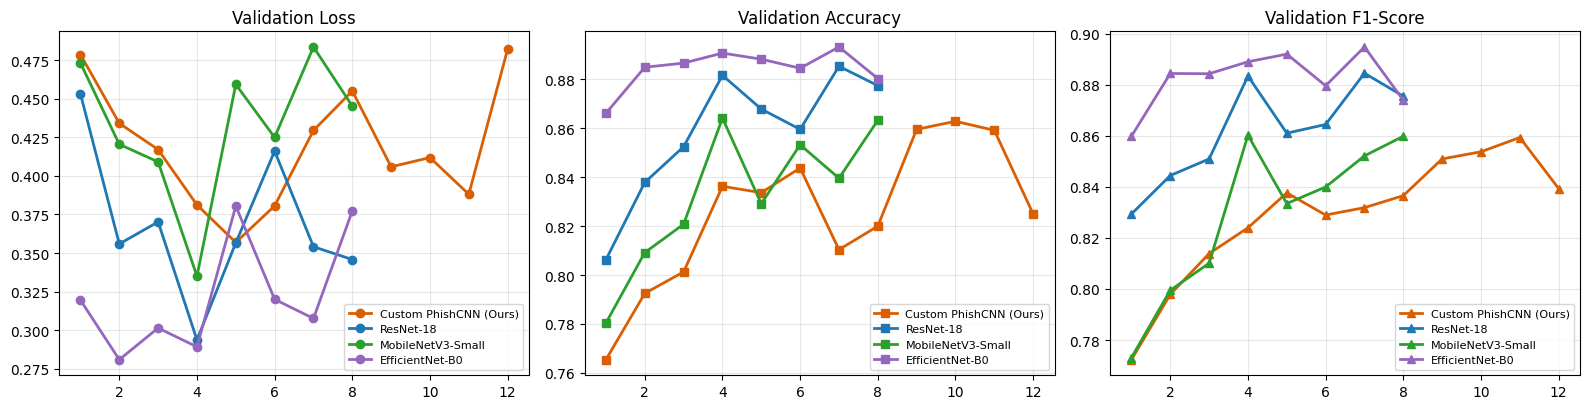

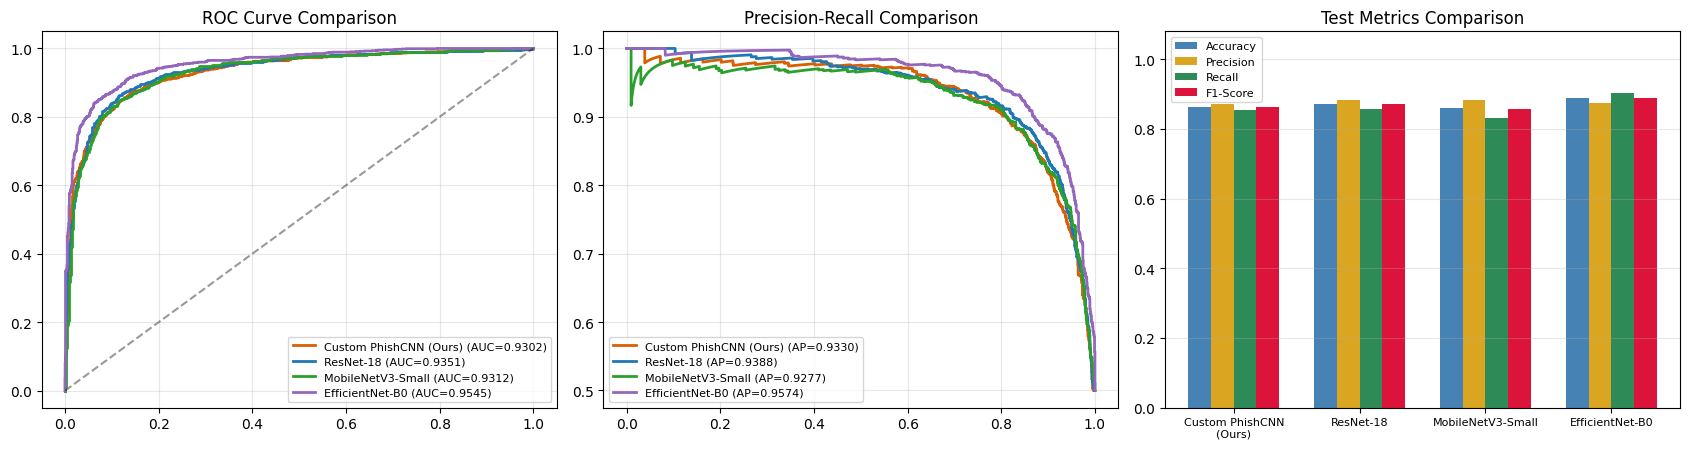

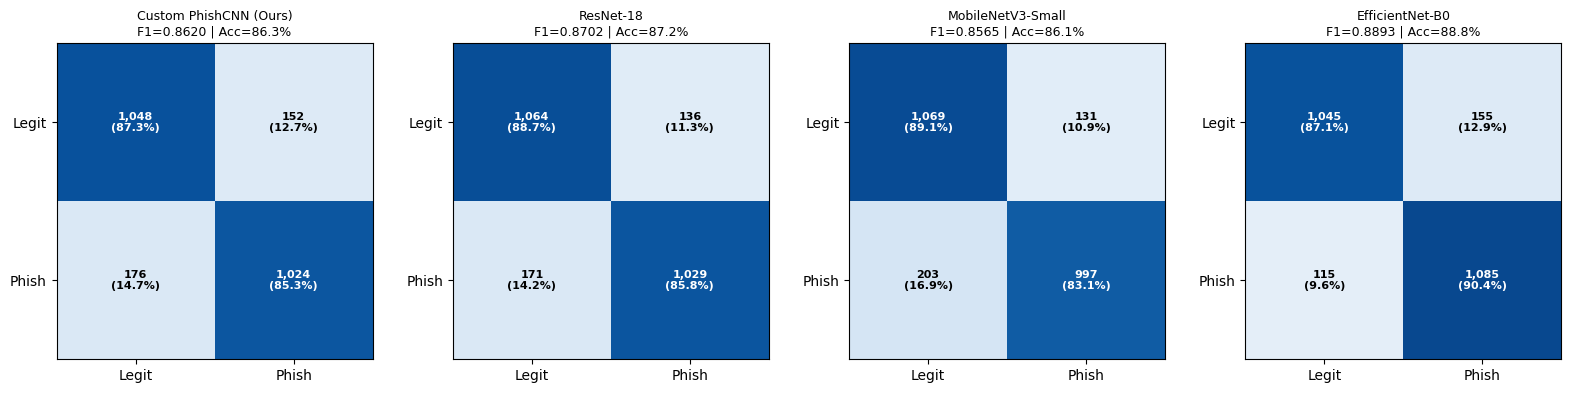

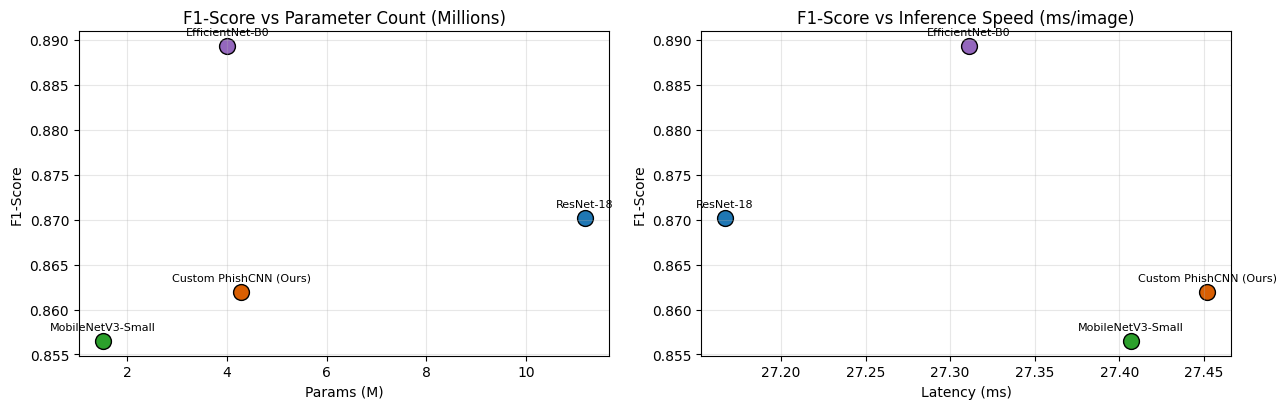

In [27]:
# Master 4-Model Benchmark Table & Comparison Visualizations
comp_rows = []
for m_name, res in benchmark_results.items():
    tn_m, fp_m, fn_m, tp_m = res['cm'].ravel() if res['cm'].size == 4 else (0, 0, 0, 0)
    comp_rows.append({
        'Model': m_name, 'Params': f"{res['params']:,}", 'Accuracy': res['acc'],
        'Balanced_Acc': res['bal_acc'], 'Precision': res['prec'], 'Recall_TPR': res['rec'],
        'Specificity_TNR': res['spec'], 'F1_Binary': res['f1'], 'F1_Macro': res['f1_macro'],
        'ROC_AUC': res['roc_auc'], 'PR_AUC': res['pr_auc'], 'MCC': res['mcc'], 'Kappa': res['kappa'],
        'TP': int(tp_m), 'TN': int(tn_m), 'FP': int(fp_m), 'FN': int(fn_m),
        'Train_Time_s': res['train_time_s'], 'Infer_ms_img': res['infer_ms']
    })

benchmark_comparison_df = pd.DataFrame(comp_rows).sort_values(by='F1_Binary', ascending=False).reset_index(drop=True)
print('=== Master Benchmark Comparison Table ===')
display(benchmark_comparison_df)
benchmark_comparison_df.to_csv('benchmark_models_comparison.csv', index=False)

model_colors = {'Custom PhishCNN (Ours)': '#d95f02', 'ResNet-18': '#1f77b4', 'MobileNetV3-Small': '#2ca02c', 'EfficientNet-B0': '#9467bd'}

# 1. Multi-Model Validation Convergence
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for m_name, res in benchmark_results.items():
    edf, clr = res['epoch_df'], model_colors.get(m_name)
    ax[0].plot(edf['Epoch'], edf['Val_Loss'], marker='o', lw=2, label=m_name, color=clr)
    ax[1].plot(edf['Epoch'], edf['Val_Acc'],  marker='s', lw=2, label=m_name, color=clr)
    ax[2].plot(edf['Epoch'], edf['Val_F1'],   marker='^', lw=2, label=m_name, color=clr)
ax[0].set_title('Validation Loss'); ax[1].set_title('Validation Accuracy'); ax[2].set_title('Validation F1-Score')
for a in ax: a.grid(True, alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

# 2. Combined ROC, PR & Grouped Metric Bar Chart
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for m_name, res in benchmark_results.items():
    clr = model_colors.get(m_name)
    fpr_m, tpr_m, _ = roc_curve(res['y_true'], res['y_prob'])
    p_m, r_m, _ = precision_recall_curve(res['y_true'], res['y_prob'])
    ax[0].plot(fpr_m, tpr_m, lw=2, color=clr, label=f"{m_name} (AUC={res['roc_auc']:.4f})")
    ax[1].plot(r_m, p_m, lw=2, color=clr, label=f"{m_name} (AP={res['pr_auc']:.4f})")
ax[0].plot([0, 1], [0, 1], 'k--', alpha=0.4); ax[0].set_title('ROC Curve Comparison'); ax[0].legend(fontsize=8); ax[0].grid(True, alpha=0.3)
ax[1].set_title('Precision-Recall Comparison'); ax[1].legend(fontsize=8); ax[1].grid(True, alpha=0.3)

m_keys = list(benchmark_results.keys())
x_idx, w_b = np.arange(len(m_keys)), 0.18
ax[2].bar(x_idx - 1.5*w_b, [benchmark_results[k]['acc'] for k in m_keys], width=w_b, label='Accuracy', color='steelblue')
ax[2].bar(x_idx - 0.5*w_b, [benchmark_results[k]['prec'] for k in m_keys], width=w_b, label='Precision', color='goldenrod')
ax[2].bar(x_idx + 0.5*w_b, [benchmark_results[k]['rec'] for k in m_keys], width=w_b, label='Recall', color='seagreen')
ax[2].bar(x_idx + 1.5*w_b, [benchmark_results[k]['f1'] for k in m_keys], width=w_b, label='F1-Score', color='crimson')
ax[2].set_xticks(x_idx); ax[2].set_xticklabels([k.replace(' (Ours)', '\n(Ours)') for k in m_keys], fontsize=8)
ax[2].set_ylim(0, 1.08); ax[2].set_title('Test Metrics Comparison'); ax[2].legend(fontsize=8); ax[2].grid(True, axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

# 3. Side-by-Side Confusion Matrices & Efficiency Scatter
fig, axes = plt.subplots(1, len(benchmark_results), figsize=(4.0 * len(benchmark_results), 3.8))
for idx, (m_name, res) in enumerate(benchmark_results.items()):
    cm_m = res['cm']
    cm_pct = cm_m.astype(float) / np.maximum(cm_m.sum(axis=1, keepdims=True), 1) * 100.0
    axes[idx].imshow(cm_pct, cmap='Blues', vmin=0, vmax=100)
    axes[idx].set_xticks([0, 1]); axes[idx].set_yticks([0, 1])
    axes[idx].set_xticklabels(['Legit', 'Phish']); axes[idx].set_yticklabels(['Legit', 'Phish'])
    axes[idx].set_title(f"{m_name}\nF1={res['f1']:.4f} | Acc={res['acc']*100:.1f}%", fontsize=9)
    for i in range(2):
        for j in range(2):
            axes[idx].text(j, i, f"{cm_m[i, j]:,}\n({cm_pct[i, j]:.1f}%)", ha='center', va='center',
                           color='white' if cm_pct[i, j] > 50 else 'black', fontweight='bold', fontsize=8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for m_name, res in benchmark_results.items():
    clr = model_colors.get(m_name, 'black')
    ax[0].scatter(res['params'] / 1e6, res['f1'], s=130, color=clr, edgecolors='black')
    ax[0].annotate(m_name, (res['params'] / 1e6, res['f1']), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)
    ax[1].scatter(res['infer_ms'], res['f1'], s=130, color=clr, edgecolors='black')
    ax[1].annotate(m_name, (res['infer_ms'], res['f1']), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)
ax[0].set_title('F1-Score vs Parameter Count (Millions)'); ax[0].set_xlabel('Params (M)'); ax[0].set_ylabel('F1-Score'); ax[0].grid(True, alpha=0.3)
ax[1].set_title('F1-Score vs Inference Speed (ms/image)'); ax[1].set_xlabel('Latency (ms)'); ax[1].set_ylabel('F1-Score'); ax[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()